In [20]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    f1_score
)

# Reprodutibilidade
np.random.seed(42)

# Caminho dos dados
RAIZ = Path("Dados")

def carregar(nome):
    return pd.read_csv(RAIZ / nome)

# Carregamento
df_orders = carregar("olist_orders_dataset.csv")
df_items = carregar("olist_order_items_dataset.csv")
df_customers = carregar("olist_customers_dataset.csv")
df_sellers = carregar("olist_sellers_dataset.csv")
df_products = carregar("olist_products_dataset.csv")
df_payments = carregar("olist_order_payments_dataset.csv")
df_geo = carregar("olist_geolocation_dataset.csv")
df_reviews = carregar("olist_order_reviews_dataset.csv")

print("Dados carregados com sucesso!")


Dados carregados com sucesso!


In [21]:

# ==========================================
# CÉLULA 1 - ENGENHARIA DE ATRIBUTOS
# ==========================================

import pandas as pd
import numpy as np

# ------------------------------------------
# 1. Conversão das datas
# ------------------------------------------

datas = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for coluna in datas:
    df_orders[coluna] = pd.to_datetime(
        df_orders[coluna], errors="coerce"
    )

# ------------------------------------------
# 2. Geolocalização
# ------------------------------------------

df_geo["geolocation_zip_code_prefix"] = (
    df_geo["geolocation_zip_code_prefix"]
    .astype(str).str.zfill(5)
)

geo = df_geo.groupby(
    "geolocation_zip_code_prefix",
    as_index=False
).agg(
    latitude=("geolocation_lat", "mean"),
    longitude=("geolocation_lng", "mean")
)

# Coordenadas dos clientes
df_customers["customer_zip_code_prefix"] = (
    df_customers["customer_zip_code_prefix"]
    .astype(str).str.zfill(5)
)

clientes = df_customers.merge(
    geo,
    left_on="customer_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left"
).rename(columns={
    "latitude": "customer_lat",
    "longitude": "customer_lng"
})

# Coordenadas dos vendedores
df_sellers["seller_zip_code_prefix"] = (
    df_sellers["seller_zip_code_prefix"]
    .astype(str).str.zfill(5)
)

vendedores = df_sellers.merge(
    geo,
    left_on="seller_zip_code_prefix",
    right_on="geolocation_zip_code_prefix",
    how="left"
).rename(columns={
    "latitude": "seller_lat",
    "longitude": "seller_lng"
})

# ------------------------------------------
# 3. Integração dos itens, produtos e vendedores
# ------------------------------------------

itens = df_items.merge(
    df_products,
    on="product_id",
    how="left"
).merge(
    vendedores[
        ["seller_id", "seller_state", "seller_lat", "seller_lng"]
    ],
    on="seller_id",
    how="left"
)

# ------------------------------------------
# 4. Características dos produtos
# ------------------------------------------

# Volume individual do produto
itens["product_volume_cm3"] = (
    itens["product_length_cm"] *
    itens["product_height_cm"] *
    itens["product_width_cm"]
)

# ------------------------------------------
# 5. Histórico de vendas dos vendedores
# ------------------------------------------

# Associar a data da compra aos itens
itens = itens.merge(
    df_orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left"
)

# Um registro por pedido e vendedor
historico_vendedor = (
    itens[["order_id", "seller_id", "order_purchase_timestamp"]]
    .drop_duplicates()
    .sort_values("order_purchase_timestamp")
    .copy()
)

# Quantidade de pedidos anteriores por vendedor.
# O pedido atual não entra na contagem.
historico_vendedor["volume_vendas_vendedor"] = (
    historico_vendedor.groupby("seller_id").cumcount()
)

# Associar o histórico aos itens
itens = itens.merge(
    historico_vendedor[
        ["order_id", "seller_id", "volume_vendas_vendedor"]
    ],
    on=["order_id", "seller_id"],
    how="left"
)

# ------------------------------------------
# 6. Função para obter a moda
# ------------------------------------------

def moda(coluna):
    valores = coluna.mode()
    return valores.iloc[0] if not valores.empty else np.nan

# ------------------------------------------
# 7. Agregação dos itens por pedido
# ------------------------------------------

itens_agg = itens.groupby("order_id").agg(

    # Características gerais
    item_count=("order_item_id", "count"),
    seller_count=("seller_id", "nunique"),
    product_count=("product_id", "nunique"),

    # Características financeiras
    price_sum=("price", "sum"),
    freight_sum=("freight_value", "sum"),

    # Atributo do GMM - rota
    freight_value=("freight_value", "sum"),

    # Características dos produtos
    weight_sum=("product_weight_g", "sum"),
    volume_sum=("product_volume_cm3", "sum"),

    # Atributos do GMM - produto
    product_weight_g=("product_weight_g", "mean"),
    product_volume_cm3=("product_volume_cm3", "mean"),

    # Atributo do GMM - vendedor
    volume_vendas_vendedor=("volume_vendas_vendedor", "mean"),

    # Características categóricas
    product_category=("product_category_name", moda),
    seller_state=("seller_state", moda),

    # Coordenadas médias dos vendedores
    seller_lat=("seller_lat", "mean"),
    seller_lng=("seller_lng", "mean")

).reset_index()

# ------------------------------------------
# 8. Agregação dos pagamentos
# ------------------------------------------

pagamentos = df_payments.groupby("order_id").agg(
    payment_value=("payment_value", "sum"),
    payment_installments=("payment_installments", "max"),
    payment_type=("payment_type", moda)
).reset_index()

# ------------------------------------------
# 9. Integração geral
# ------------------------------------------

df = df_orders.merge(
    clientes[
        ["customer_id", "customer_state", "customer_lat", "customer_lng"]
    ],
    on="customer_id",
    how="left"
)

df = df.merge(
    itens_agg,
    on="order_id",
    how="left"
)

df = df.merge(
    pagamentos,
    on="order_id",
    how="left"
)

# ------------------------------------------
# 10. Distância entre cliente e vendedor
# ------------------------------------------

def haversine(lat1, lon1, lat2, lon2):

    raio = 6371

    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2 +
        np.cos(lat1) * np.cos(lat2) *
        np.sin(dlon / 2) ** 2
    )

    return 2 * raio * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(
    df["customer_lat"],
    df["customer_lng"],
    df["seller_lat"],
    df["seller_lng"]
)

# ------------------------------------------
# 11. Tempo de postagem
# ------------------------------------------

df["tempo_postagem_horas"] = (
    df["order_delivered_carrier_date"] -
    df["order_approved_at"]
).dt.total_seconds() / 3600

# ------------------------------------------
# 12. Tempo entre compra e aprovação
# ------------------------------------------

df["approval_minutes"] = (
    df["order_approved_at"] -
    df["order_purchase_timestamp"]
).dt.total_seconds() / 60

# ------------------------------------------
# 13. Características temporais
# ------------------------------------------

df["purchase_month"] = (
    df["order_purchase_timestamp"].dt.month
)

df["purchase_day"] = (
    df["order_purchase_timestamp"].dt.dayofweek
)

df["purchase_hour"] = (
    df["order_purchase_timestamp"].dt.hour
)

df["purchase_weekend"] = (
    df["purchase_day"] >= 5
).astype(int)

# ------------------------------------------
# 14. Variável-alvo
# ------------------------------------------

df["delay_days"] = (
    df["order_delivered_customer_date"] -
    df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Somente pedidos efetivamente entregues
df = df[
    (df["order_status"] == "delivered") &
    df["order_delivered_customer_date"].notna() &
    df["order_estimated_delivery_date"].notna() &
    df["order_approved_at"].notna()
].copy()

# Classificação binária
df["atrasado"] = (df["delay_days"] > 0).astype(int)

# ------------------------------------------
# 15. Visualização dos resultados
# ------------------------------------------

atributos_gmm = [
    "freight_value",
    "distance_km",
    "tempo_postagem_horas",
    "volume_vendas_vendedor",
    "product_weight_g",
    "product_volume_cm3",
    "customer_lat",
    "customer_lng"
]

print("Atributos do GMM:")
print(df[atributos_gmm].describe())

print("\nDistribuição da variável-alvo:")
print(df["atrasado"].value_counts(normalize=True))

print("\nAmostra:")
print(df[["order_id"] + atributos_gmm + ["atrasado"]].head())


# ------------------------------------------
# 16. Prazos da promessa e localização
# ------------------------------------------
# São conhecidos após a postagem; NUNCA utilizam a data de entrega real.
df["prazo_prometido_dias"] = (
    df["order_estimated_delivery_date"] - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400
df["prazo_restante_postagem_dias"] = (
    df["order_estimated_delivery_date"] - df["order_delivered_carrier_date"]
).dt.total_seconds() / 86400
df["prazo_apos_aprovacao_dias"] = (
    df["order_estimated_delivery_date"] - df["order_approved_at"]
).dt.total_seconds() / 86400
df["mesmo_estado_vendedor_cliente"] = np.where(
    df["seller_state"].notna() & df["customer_state"].notna(),
    (df["seller_state"] == df["customer_state"]).astype(float),
    np.nan
)


Atributos do GMM:
       freight_value   distance_km  tempo_postagem_horas  \
count   96456.000000  95980.000000          96455.000000   
mean       22.786159    600.405023             67.177166   
std        21.561315    593.522395             84.892152   
min         0.000000      0.000000          -4109.256111   
25%        13.850000    186.045216             20.980972   
50%        17.170000    433.384885             43.579444   
75%        24.020000    797.603279             85.798333   
max      1794.960000   8677.911622           3018.301667   

       volume_vendas_vendedor  product_weight_g  product_volume_cm3  \
count            96456.000000      96440.000000        96440.000000   
mean               187.941002       2098.157715        15152.498364   
std                302.732617       3744.777705        23216.818360   
min                  0.000000          0.000000          168.000000   
25%                 16.000000        300.000000         2816.000000   
50%            

C:\Users\cpedr\AppData\Local\Temp\ipykernel_22652\708469515.py:273: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["order_purchase_timestamp"].dt.dayofweek


<class 'pandas.DataFrame'>
Index: 96456 entries, 0 to 99440
Data columns (total 42 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       96456 non-null  str           
 1   customer_id                    96456 non-null  str           
 2   order_status                   96456 non-null  str           
 3   order_purchase_timestamp       96456 non-null  datetime64[us]
 4   order_approved_at              96456 non-null  datetime64[us]
 5   order_delivered_carrier_date   96455 non-null  datetime64[us]
 6   order_delivered_customer_date  96456 non-null  datetime64[us]
 7   order_estimated_delivery_date  96456 non-null  datetime64[us]
 8   customer_state                 96456 non-null  str           
 9   customer_lat                   96192 non-null  float64       
 10  customer_lng                   96192 non-null  float64       
 11  item_count                     

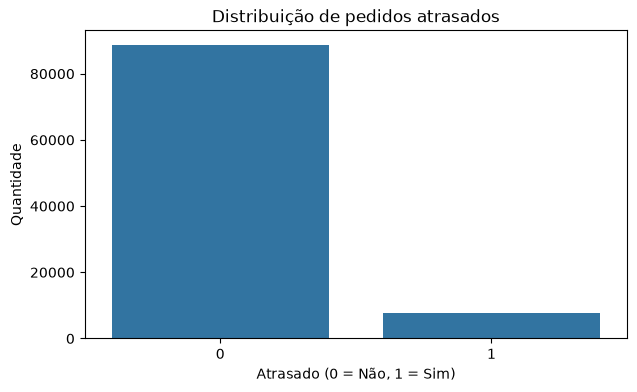

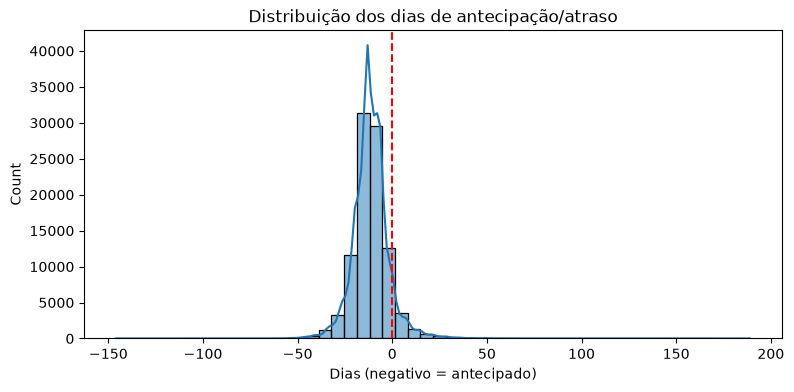

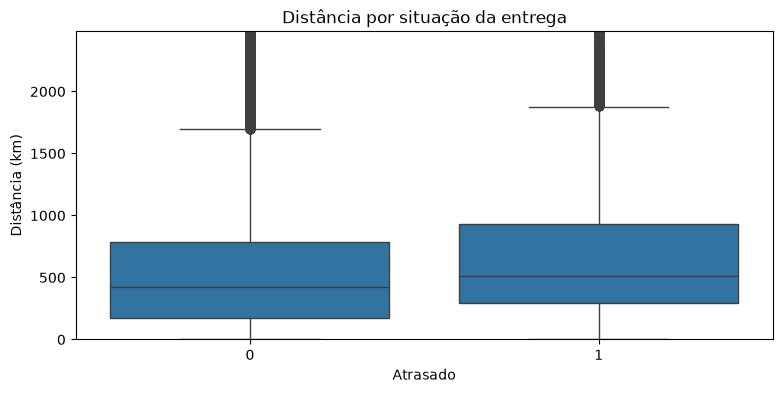

KeyboardInterrupt: 

In [22]:

# 1. Informações gerais
print(df.info())

print("\nEstatísticas descritivas:")
print(df.describe())

print("\nValores ausentes:")
print(df.isna().sum().sort_values(ascending=False))

# 2. Distribuição da variável-alvo
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="atrasado")
plt.title("Distribuição de pedidos atrasados")
plt.xlabel("Atrasado (0 = Não, 1 = Sim)")
plt.ylabel("Quantidade")
plt.show()

# 3. Distribuição dos dias de atraso
plt.figure(figsize=(9, 4))
sns.histplot(df["delay_days"], bins=50, kde=True)
plt.axvline(0, linestyle="--", color="red")
plt.title("Distribuição dos dias de antecipação/atraso")
plt.xlabel("Dias (negativo = antecipado)")
plt.show()

# 4. Relação entre distância e atraso
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="atrasado", y="distance_km")
plt.title("Distância por situação da entrega")
plt.xlabel("Atrasado")
plt.ylabel("Distância (km)")
plt.ylim(0, df["distance_km"].quantile(0.99))
plt.show()

# 5. Taxa de atraso por estado do cliente
atrasos_estado = (
    df.groupby("customer_state")["atrasado"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 5))
atrasos_estado.plot(kind="bar")
plt.title("Taxa de atraso por estado do cliente")
plt.ylabel("Proporção de atrasos")
plt.show()

# 6. Taxa de atraso por categoria
atrasos_categoria = (
    df.groupby("product_category")["atrasado"]
    .agg(["mean", "count"])
    .query("count >= 100")
    .sort_values("mean", ascending=False)
)

plt.figure(figsize=(12, 6))
atrasos_categoria["mean"].head(15).plot(kind="bar")
plt.title("15 categorias com maior taxa de atraso")
plt.ylabel("Proporção de atrasos")
plt.show()

# 7. Evolução mensal
df["purchase_period"] = (
    df["order_purchase_timestamp"].dt.to_period("M").astype(str)
)

atrasos_mes = df.groupby("purchase_period")["atrasado"].mean()

plt.figure(figsize=(13, 5))
atrasos_mes.plot(marker="o")
plt.title("Evolução mensal da taxa de atraso")
plt.xticks(rotation=90)
plt.ylabel("Proporção de atrasos")
plt.show()

# 8. Correlação entre variáveis numéricas
numericas = df.select_dtypes(include=np.number)

plt.figure(figsize=(13, 9))
sns.heatmap(
    numericas.corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Matriz de correlação")
plt.show()


In [ ]:
# ==========================================
# CÉLULA 2 - FEATURES, DIVISÃO TEMPORAL E BALANCEAMENTO
# ==========================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.utils import resample

# ------------------------------------------
# 1. Features utilizadas pelo GMM
# ------------------------------------------

features_rota = [
    "freight_value",
    "distance_km"
]

features_vendedor = [
    "tempo_postagem_horas",
    "volume_vendas_vendedor"
]

features_produto = [
    "product_weight_g",
    "product_volume_cm3"
]

# Coordenadas do cliente usadas pelo GMM geográfico.
features_geo = ["customer_lat", "customer_lng"]

# Todas as características do GMM
features_gmm = (
    features_rota +
    features_vendedor +
    features_produto +
    features_geo
)

# ------------------------------------------
# 2. Features do modelo de classificação
# ------------------------------------------

numericas = [
    "item_count",
    "seller_count",
    "product_count",
    "price_sum",
    "freight_sum",
    "weight_sum",
    "volume_sum",
    "payment_value",
    "payment_installments",
    "approval_minutes",
    "distance_km",
    "purchase_month",
    "purchase_day",
    "purchase_hour",
    "purchase_weekend",
    # Localização do cliente: acrescentada para capturar atrasos regionais via GMM.
    "customer_lat",
    "customer_lng",
    "seller_lat",
    "seller_lng",
    "prazo_prometido_dias",
    "prazo_restante_postagem_dias",
    "prazo_apos_aprovacao_dias",
    "mesmo_estado_vendedor_cliente",

    # Novos atributos do GMM
    "freight_value",
    "tempo_postagem_horas",
    "volume_vendas_vendedor",
    "product_weight_g",
    "product_volume_cm3"
]

categoricas = [
    "customer_state",
    "seller_state",
    "product_category",
    "payment_type"
]

features = numericas + categoricas

# ------------------------------------------
# 3. Preparação da base
# ------------------------------------------

df_modelo = df.dropna(
    subset=["atrasado"]
).sort_values(
    "order_purchase_timestamp"
).copy()

X = df_modelo[features].copy()
y = df_modelo["atrasado"].copy()

# ------------------------------------------
# 4. Divisão temporal
# ------------------------------------------

n = len(df_modelo)

fim_treino = int(n * 0.70)
fim_validacao = int(n * 0.85)

X_treino = X.iloc[:fim_treino].copy()
y_treino = y.iloc[:fim_treino].copy()


X_validacao = X.iloc[fim_treino:fim_validacao].copy()
y_validacao = y.iloc[fim_treino:fim_validacao].copy()

X_teste = X.iloc[fim_validacao:].copy()
y_teste = y.iloc[fim_validacao:].copy()

# ------------------------------------------
# 5. Pré-processamento numérico
# ------------------------------------------

pipeline_numerico = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# ------------------------------------------
# 6. Pré-processamento categórico
# ------------------------------------------

pipeline_categorico = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# ------------------------------------------
# 7. Pré-processador completo
# ------------------------------------------

preprocessador = ColumnTransformer([
    ("num", pipeline_numerico, numericas),
    ("cat", pipeline_categorico, categoricas)
])

# IMPORTANTE:
# Não executar fit_transform aqui.
# O preprocessador será ajustado dentro do pipeline_completo.

# ------------------------------------------
# 8. Balanceamento por undersampling
# ------------------------------------------

dados_treino = X_treino.copy()
dados_treino["target"] = y_treino

classe_0 = dados_treino[
    dados_treino["target"] == 0
]

classe_1 = dados_treino[
    dados_treino["target"] == 1
]

# Configuração simples para experimentos:
#   PROPORCAO_CLASSE_0_PARA_1 = 3 -> treino ainda desbalanceado (3:1).
#   PROPORCAO_CLASSE_0_PARA_1 = 1 -> treino aproximadamente balanceado (1:1).
#   APLICAR_UNDERSAMPLING = False  -> manter toda a base original.
# Reduzimos a classe 0 (a mais comum); reduzir a classe 1 aumentaria o desequilíbrio.
APLICAR_UNDERSAMPLING = True
PROPORCAO_CLASSE_0_PARA_1 = 3

if APLICAR_UNDERSAMPLING:
    n_classe_0 = min(
        len(classe_0),
        len(classe_1) * PROPORCAO_CLASSE_0_PARA_1
    )
    classe_0_reduzida = resample(
        classe_0,
        replace=False,
        n_samples=n_classe_0,
        random_state=42
    )
    dados_balanceados = pd.concat([classe_0_reduzida, classe_1]).sample(
        frac=1, random_state=42
    )
else:
    dados_balanceados = dados_treino.sample(frac=1, random_state=42)

# Preservar DataFrame e nomes das colunas
X_treino_balanceado = (
    dados_balanceados.drop(columns="target")
)

y_treino_balanceado = (
    dados_balanceados["target"]
)

# ------------------------------------------
# 9. Verificação dos resultados
# ------------------------------------------

print("Atributos GMM:")
print(features_gmm)

print("\nDistribuição original:")
print(y_treino.value_counts())

print("\nDistribuição balanceada:")
print(y_treino_balanceado.value_counts())

print("\nDimensões:")

print("Treino:", X_treino.shape)
print("Treino balanceado:", X_treino_balanceado.shape)
print("Validação:", X_validacao.shape)
print("Teste:", X_teste.shape)

print("\nTipo dos dados:")
print(type(X_treino_balanceado))

print("\nColunas preservadas:")
print(X_treino_balanceado.columns.tolist())


Atributos GMM:
['freight_value', 'distance_km', 'tempo_postagem_horas', 'volume_vendas_vendedor', 'product_weight_g', 'product_volume_cm3', 'customer_lat', 'customer_lng']

Distribuição original:
atrasado
0    61423
1     6096
Name: count, dtype: int64

Distribuição balanceada:
target
0    18288
1     6096
Name: count, dtype: int64

Dimensões:
Treino: (67519, 32)
Treino balanceado: (24384, 32)
Validação: (14468, 32)
Teste: (14469, 32)

Tipo dos dados:
<class 'pandas.DataFrame'>

Colunas preservadas:
['item_count', 'seller_count', 'product_count', 'price_sum', 'freight_sum', 'weight_sum', 'volume_sum', 'payment_value', 'payment_installments', 'approval_minutes', 'distance_km', 'purchase_month', 'purchase_day', 'purchase_hour', 'purchase_weekend', 'customer_lat', 'customer_lng', 'seller_lat', 'seller_lng', 'prazo_prometido_dias', 'prazo_restante_postagem_dias', 'prazo_apos_aprovacao_dias', 'mesmo_estado_vendedor_cliente', 'freight_value', 'tempo_postagem_horas', 'volume_vendas_vendedor',

# Predição de atrasos — Olist | comparação e otimização de modelos

Este notebook preserva a engenharia de atributos, o tratamento dos dados, os **gráficos exploratórios anteriores** e a divisão **cronológica em treino (70%), validação (15%) e teste (15%)**.

**Objetivo:** melhorar a detecção da classe **1 = entrega atrasada** sem confundir precisão (*precision*) com revocação (*recall*). Novos atributos de prazo prometido, prazo após postagem e localização do vendedor são adicionados sem utilizar a data da entrega real. Os quatro GMMs (rota, vendedor, produto e geografia) aprendem somente com o conjunto de treino e geram novas características. São comparados Random Forest, Extra Trees, regressão logística e HistGradientBoosting; XGBoost e LightGBM entram automaticamente quando instalados. Inclui-se Random Forest **sem GMM** para verificar se os clusters realmente ajudam. A rede neural permanece comentada.

**Regras de avaliação:**
- Treinar sempre com `X_treino_balanceado`, `y_treino_balanceado` (se `APLICAR_UNDERSAMPLING=False`, essas variáveis contêm o treino integral).
- Ajustar hiperparâmetros e o **limiar** somente na validação; selecionar o vencedor por **F1 da classe 1 na validação** (empate: PR-AUC). O teste **não** determina hiperparâmetros nem limiar.
- Para **cada modelo**, avaliar treino usado no ajuste, treino original, validação e teste: matriz de confusão, relatório, curvas Precision–Recall e ROC, e métricas comparativas.
- Teste sem balanceamento (proporção real); desempenho no treino balanceado pode parecer artificialmente melhor que no teste.

**Importante:** nenhuma melhora é garantida antes de executar com seus CSVs. Não há CSVs do Olist neste arquivo; coloque-os na pasta `Dados/`. A taxa de atraso deve ser comparada com a **precisão-base** da classe 1. Como `tempo_postagem_horas` só é conhecido após a postagem, esta experiência modela previsão **após a postagem**, não no instante da compra. Não use `delay_days`, datas de entrega realizadas ou a variável `atrasado` como preditoras.

In [ ]:
# Configuração do experimento — altere aqui antes de executar.
import os
import warnings
import joblib
import cloudpickle
from copy import deepcopy
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve,
    roc_curve
)
from sklearn.pipeline import Pipeline
from scipy import sparse

SEMENTE = 42
# Busca controlada: 3 configurações por modelo; reduza para 1 se quiser testar execução.
MAX_CONFIG_POR_MODELO = 3
BETA_OTIMIZACAO = 1.0         # 1 = F1, > 1 dá mais importância ao recall
PRECISAO_MINIMA = None        # Ex.: 0.20 (se possível na validação) ou None
MIN_PREVISOES_POSITIVAS = 10  # evita escolher um limiar que marca quase nenhum atraso
ATIVAR_XGBOOST = True         # se não instalado, será ignorado sem travar
ATIVAR_LIGHTGBM = True        # se não instalado, será ignorado sem travar
# Cada modelo tem suas configurações avaliadas apenas na validação.

for nome_y, ys in [
    ("Treino original", y_treino), ("Treino usado no fit", y_treino_balanceado),
    ("Validação", y_validacao), ("Teste", y_teste)
]:
    ys = np.asarray(ys).astype(int).ravel()
    print(f"{nome_y:21s} N={len(ys):>6d} | atraso={ys.mean():.2%} | classes={np.unique(ys)}")
    if len(np.unique(ys)) < 2:
        raise ValueError(f"{nome_y} precisa ter as classes 0 e 1 para comparar os modelos.")

y_treino = y_treino.astype(int)
y_treino_balanceado = y_treino_balanceado.astype(int)
y_validacao = y_validacao.astype(int)
y_teste = y_teste.astype(int)

modelos = {}                # Pipelines com transformador e classificador já ajustados
parametros_vencedores = {}
limiares_validados = {}
resultados_validacao = {}
resultados_configuracoes = []
resultados_por_divisao = []
probs_por_modelo = {}
historicos = {}              # MLP fica desativada

Treino original       N= 67519 | atraso=9.03% | classes=[0 1]
Treino usado no fit   N= 24384 | atraso=25.00% | classes=[0 1]
Validação             N= 14468 | atraso=5.34% | classes=[0 1]
Teste                 N= 14469 | atraso=6.61% | classes=[0 1]


In [ ]:
# Funções para escolher o limiar e avaliar SEM consultar o teste no tuning.
def escolher_limiar(y_real, probabilidades, beta=BETA_OTIMIZACAO,
                    precisao_minima=PRECISAO_MINIMA):
    y_arr = np.asarray(y_real).astype(int).ravel()
    prob = np.asarray(probabilidades).ravel()
    precision, recall, thresholds = precision_recall_curve(y_arr, prob)
    if len(thresholds) == 0:
        return 0.5
    b2 = beta ** 2
    scores = ((1 + b2) * precision[:-1] * recall[:-1] /
              (b2 * precision[:-1] + recall[:-1] + 1e-12))
    n_previstas = np.array([(prob >= t).sum() for t in thresholds])
    mascara = n_previstas >= min(MIN_PREVISOES_POSITIVAS, len(prob))
    if precisao_minima is not None:
        com_restricao = mascara & (precision[:-1] >= precisao_minima)
        if com_restricao.any():
            mascara = com_restricao
        else:
            print(f"  Aviso: precisão mínima {precisao_minima:.1%} não foi alcançada; usando melhor F-beta.")
    if not mascara.any():
        mascara = np.ones(len(thresholds), dtype=bool)
    indice = int(np.argmax(np.where(mascara, scores, -np.inf)))
    return float(thresholds[indice])


def calcular_metricas(y_real, probabilidades, limiar):
    y_arr = np.asarray(y_real).astype(int).ravel()
    p = np.asarray(probabilidades).ravel()
    y_prev = (p >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_arr, y_prev, labels=[0, 1]).ravel()
    resultado = {
        "limiar": float(limiar), "amostras": len(y_arr),
        "taxa_atraso": float(y_arr.mean()), "previstos_atrasos": int(y_prev.sum()),
        "accuracy": accuracy_score(y_arr, y_prev),
        "precision": precision_score(y_arr, y_prev, zero_division=0),
        "recall": recall_score(y_arr, y_prev, zero_division=0),
        "f1": f1_score(y_arr, y_prev, zero_division=0),
        "f_beta": fbeta_score(y_arr, y_prev, beta=BETA_OTIMIZACAO, zero_division=0),
        "pr_auc": average_precision_score(y_arr, p) if len(np.unique(y_arr)) == 2 else np.nan,
        "roc_auc": roc_auc_score(y_arr, p) if len(np.unique(y_arr)) == 2 else np.nan,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    return resultado


def exibir_metricas(nome, divisao, y_real, probabilidades, limiar):
    m = calcular_metricas(y_real, probabilidades, limiar)
    print(f"{nome} | {divisao} | n={m['amostras']} | limiar={limiar:.4f}")
    print(f"Precisão={m['precision']:.4f} | Recall={m['recall']:.4f} | F1={m['f1']:.4f} | PR-AUC={m['pr_auc']:.4f} | ROC-AUC={m['roc_auc']:.4f}")
    print(classification_report(np.asarray(y_real).ravel(),
          (np.asarray(probabilidades).ravel() >= limiar).astype(int),
          labels=[0, 1], target_names=['No prazo', 'Atrasado'], zero_division=0))
    return m

In [ ]:
# ==============================================================
# GMM (clusters não supervisionados) + Random Forest (classificador)
# ==============================================================
from scipy import sparse
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.mixture import GaussianMixture
from sklearn.utils.validation import check_is_fitted


class GMMFeatures(BaseEstimator, TransformerMixin):
    """Transforma cada amostra em probabilidades para os clusters do GMM."""

    def __init__(self, n_components=3, random_state=42):
        self.n_components = n_components
        self.random_state = random_state

    def fit(self, X, y=None):
        self.gmm_ = GaussianMixture(
            n_components=self.n_components,
            covariance_type="full",
            reg_covar=1e-5,
            random_state=self.random_state
        )
        self.gmm_.fit(X)  # O rótulo y NÃO participa do agrupamento.
        return self

    def transform(self, X):
        check_is_fitted(self, "gmm_")
        return self.gmm_.predict_proba(X)


def criar_pipeline_gmm(n_components):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler()),
        ("gmm", GMMFeatures(n_components=n_components, random_state=42))
    ])


class CriadorGMM(BaseEstimator, TransformerMixin):
    """Concatena probabilidades dos GMMs + atributos numéricos/categóricos.

    Usa scipy.sparse.hstack para unir matrizes densas de GMM a saídas
    possivelmente esparsas do OneHotEncoder, sem o erro de dimensões do np.hstack.
    """

    def __init__(self, n_clusters_rota=4, n_clusters_vendedor=3,
                 n_clusters_produto=3, n_clusters_geo=6):
        self.n_clusters_rota = n_clusters_rota
        self.n_clusters_vendedor = n_clusters_vendedor
        self.n_clusters_produto = n_clusters_produto
        self.n_clusters_geo = n_clusters_geo

    def fit(self, X, y=None):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("O CriadorGMM exige um pandas.DataFrame com nomes de colunas.")

        self.features_rota_ = ["freight_value", "distance_km"]
        self.features_vendedor_ = ["tempo_postagem_horas", "volume_vendas_vendedor"]
        self.features_produto_ = ["product_weight_g", "product_volume_cm3"]
        self.features_geo_ = ["customer_lat", "customer_lng"]
        self.colunas_ = X.columns.tolist()
        exigidas = (self.features_rota_ + self.features_vendedor_ +
                    self.features_produto_ + self.features_geo_)
        faltantes = sorted(set(exigidas) - set(X.columns))
        if faltantes:
            raise ValueError(f"Colunas necessárias aos GMMs ausentes: {faltantes}")

        self.gmm_rota_ = criar_pipeline_gmm(self.n_clusters_rota)
        self.gmm_vendedor_ = criar_pipeline_gmm(self.n_clusters_vendedor)
        self.gmm_produto_ = criar_pipeline_gmm(self.n_clusters_produto)
        self.gmm_geo_ = criar_pipeline_gmm(self.n_clusters_geo)

        self.gmm_rota_.fit(X[self.features_rota_])
        self.gmm_vendedor_.fit(X[self.features_vendedor_])
        self.gmm_produto_.fit(X[self.features_produto_])
        self.gmm_geo_.fit(X[self.features_geo_])

        # Conservar TODOS os atributos originais, inclusive os usados nos GMMs.
        # Isso permite ao Random Forest combinar informações brutas + clusters.
        self.numericas_ = X.select_dtypes(include="number").columns.tolist()
        self.categoricas_ = [c for c in self.colunas_ if c not in self.numericas_]

        self.processador_restante_ = ColumnTransformer(
            transformers=[
                ("num", SimpleImputer(strategy="median", keep_empty_features=True),
                 self.numericas_),
                ("cat", Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent",
                                              keep_empty_features=True)),
                    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
                ]), self.categoricas_)
            ],
            remainder="drop",
            sparse_threshold=1.0
        )
        self.processador_restante_.fit(X)
        return self

    def transform(self, X):
        check_is_fitted(self, "processador_restante_")
        if not isinstance(X, pd.DataFrame):
            raise TypeError("Passe um DataFrame também em predict/predict_proba.")

        prob_rota = self.gmm_rota_.transform(X[self.features_rota_])
        prob_vendedor = self.gmm_vendedor_.transform(X[self.features_vendedor_])
        prob_produto = self.gmm_produto_.transform(X[self.features_produto_])
        prob_geo = self.gmm_geo_.transform(X[self.features_geo_])
        originais = self.processador_restante_.transform(X)

        # hstack do scipy combina corretamente matrizes 2D densas e esparsas.
        return sparse.hstack(
            [sparse.csr_matrix(parte) for parte in
             (prob_rota, prob_vendedor, prob_produto, prob_geo, originais)],
            format="csr"
        )

In [ ]:
class DensificarMatriz:
    # Etapa sem estado, necessária para prever no pipeline HistGradientBoosting.
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        if not sparse.issparse(X):
            return X
        tamanho_gib = X.shape[0] * X.shape[1] * 8 / (1024 ** 3)
        if tamanho_gib > 1.25:
            raise MemoryError(f"Matriz densa excederia ~{tamanho_gib:.2f} GiB")
        return X.toarray()

# Ajustar a engenharia de características SOMENTE no treino utilizado.
# A mesma transformação é reutilizada por todos os classificadores —
# mais eficiente do que treinar quatro GMMs para cada combinação de hiperparâmetros.
transformador_gmm = CriadorGMM(n_clusters_rota=4, n_clusters_vendedor=3,
                                n_clusters_produto=3, n_clusters_geo=6)
transformador_gmm.fit(X_treino_balanceado)

matrizes_gmm = {
    "Treino (ajuste)": transformador_gmm.transform(X_treino_balanceado),
    "Treino original": transformador_gmm.transform(X_treino),
    "Validação": transformador_gmm.transform(X_validacao),
    "Teste": transformador_gmm.transform(X_teste),
}

# Experimento de ablação: mesmos classificadores, mas SEM probabilidades GMM.
preprocessador_sem_gmm = clone(preprocessador)
preprocessador_sem_gmm.fit(X_treino_balanceado)
matrizes_sem_gmm = {
    "Treino (ajuste)": preprocessador_sem_gmm.transform(X_treino_balanceado),
    "Treino original": preprocessador_sem_gmm.transform(X_treino),
    "Validação": preprocessador_sem_gmm.transform(X_validacao),
    "Teste": preprocessador_sem_gmm.transform(X_teste),
}

alvos = {
    "Treino (ajuste)": y_treino_balanceado,
    "Treino original": y_treino,
    "Validação": y_validacao,
    "Teste": y_teste,
}

print("GMM: matriz após transformação:", matrizes_gmm['Treino (ajuste)'].shape)
print("Sem GMM: matriz após transformação:", matrizes_sem_gmm['Treino (ajuste)'].shape)
print("Nota: as matrizes de validação/teste foram somente transformadas, nunca ajustadas.")

GMM: matriz após transformação: (24384, 169)
Sem GMM: matriz após transformação: (24384, 153)
Nota: as matrizes de validação/teste foram somente transformadas, nunca ajustadas.


Clusters geográficos dos clientes na validação:


,cluster_geo,pedidos,taxa_atraso
0,0,679,0.144
5,5,601,0.128
1,1,1064,0.075
4,4,3628,0.064
2,2,4751,0.034
3,3,3745,0.033


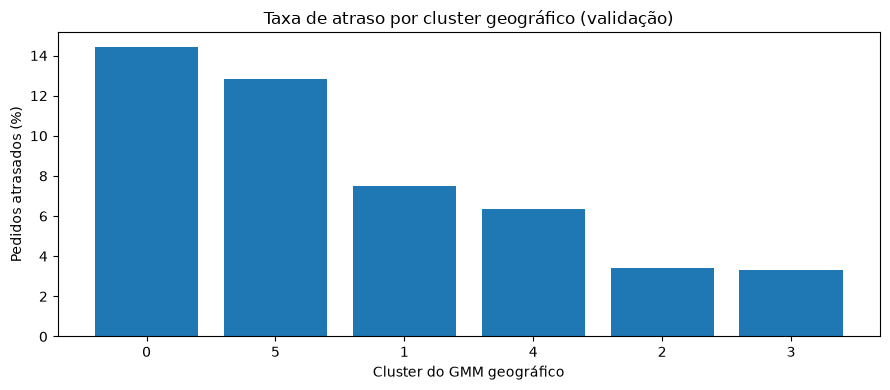

In [ ]:
# Diagnóstico de localidades: desempenho por cluster geográfico na VALIDAÇÃO.
# O GMM agrupa pelas coordenadas do cliente, SEM conhecer y_validacao.
transformador = transformador_gmm
probs_geo_val = transformador.gmm_geo_.transform(X_validacao[transformador.features_geo_])
clusters_geo_val = probs_geo_val.argmax(axis=1)

analise_geo = pd.DataFrame({
    "cluster_geo": clusters_geo_val,
    "atrasado": y_validacao.to_numpy()
})
resumo_geo = (
    analise_geo.groupby("cluster_geo", as_index=False)
    .agg(pedidos=("atrasado", "size"), taxa_atraso=("atrasado", "mean"))
    .sort_values("taxa_atraso", ascending=False)
)
print("Clusters geográficos dos clientes na validação:")
display(resumo_geo.round(3))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(resumo_geo["cluster_geo"].astype(str), 100 * resumo_geo["taxa_atraso"])
ax.set_title("Taxa de atraso por cluster geográfico (validação)")
ax.set_xlabel("Cluster do GMM geográfico")
ax.set_ylabel("Pedidos atrasados (%)")
plt.tight_layout()
plt.show()

In [ ]:
# Catálogo de modelos e hiperparâmetros: pelo menos 3 configurações de cada família.
# Para priorizar recall em vez de F1, aumente BETA_OTIMIZACAO na célula de configuração.

def especificacoes_modelos():
    cw = {"random_state": SEMENTE, "n_jobs": -1, "n_estimators": 220}
    specs = {
        "GMM + Random Forest": {
            "usa_gmm": True, "classe": RandomForestClassifier, "base": cw,
            "configuracoes": [
                {"max_depth": 12, "min_samples_leaf": 2, "max_features": "sqrt", "class_weight": None},
                {"max_depth": 18, "min_samples_leaf": 4, "max_features": "sqrt", "class_weight": "balanced_subsample"},
                {"max_depth": None, "min_samples_leaf": 8, "max_features": 0.7, "class_weight": None},
                {"max_depth": 12, "min_samples_leaf": 10, "max_features": "sqrt", "class_weight": None},
            ]
        },
        "GMM + Extra Trees": {
            "usa_gmm": True, "classe": ExtraTreesClassifier, "base": cw,
            "configuracoes": [
                {"max_depth": 16, "min_samples_leaf": 2, "max_features": "sqrt", "class_weight": None},
                {"max_depth": None, "min_samples_leaf": 5, "max_features": 0.7, "class_weight": "balanced"},
                {"max_depth": 22, "min_samples_leaf": 8, "max_features": "sqrt", "class_weight": None},
                {"max_depth": 30, "min_samples_leaf": 16, "max_features": "sqrt", "class_weight": None},
            ]
        },
        "GMM + Regressão Logística": {
            "usa_gmm": True, "classe": LogisticRegression,
            "base": {"solver": "liblinear", "max_iter": 1200, "random_state": SEMENTE},
            "configuracoes": [
                {"C": 0.1, "class_weight": None},
                {"C": 1.0, "class_weight": "balanced"},
                {"C": 3.0, "class_weight": None},
            ]
        },
        "GMM + HistGradientBoosting": {
            "usa_gmm": True, "classe": HistGradientBoostingClassifier,
            "base": {"random_state": SEMENTE, "early_stopping": True},
            "densificar": True,
            "configuracoes": [
                {"max_iter": 180, "max_leaf_nodes": 15, "learning_rate": 0.05, "l2_regularization": 1.0},
                {"max_iter": 230, "max_leaf_nodes": 31, "learning_rate": 0.05, "l2_regularization": 0.0},
                {"max_iter": 260, "max_leaf_nodes": 15, "learning_rate": 0.10, "l2_regularization": 2.0},
            ]
        },
        "Sem GMM + Random Forest": {
            "usa_gmm": False, "classe": RandomForestClassifier, "base": cw,
            "configuracoes": [
                {"max_depth": 12, "min_samples_leaf": 2, "max_features": "sqrt", "class_weight": None},
                {"max_depth": 18, "min_samples_leaf": 4, "max_features": "sqrt", "class_weight": "balanced_subsample"},
                {"max_depth": 30, "min_samples_leaf": 10, "max_features": "sqrt", "class_weight": "balanced_subsample"},
                {"max_depth": 30, "min_samples_leaf": 10, "max_features": "sqrt", "class_weight": None},
                {"max_depth": None, "min_samples_leaf": 8, "max_features": 0.7, "class_weight": None},
            ]
        }
    }
    if ATIVAR_XGBOOST:
        try:
            from xgboost import XGBClassifier
            specs["GMM + XGBoost"] = {
                "usa_gmm": True, "classe": XGBClassifier,
                "base": {"random_state": SEMENTE, "n_jobs": 4,
                         "tree_method": "hist", "objective": "binary:logistic", "eval_metric": "logloss"},
                "configuracoes": [
                    {"n_estimators": 250, "max_depth": 3, "learning_rate": 0.06, "subsample": 0.85, "colsample_bytree": 0.85},
                    {"n_estimators": 400, "max_depth": 5, "learning_rate": 0.04, "subsample": 0.9, "colsample_bytree": 0.9},
                    {"n_estimators": 260, "max_depth": 4, "learning_rate": 0.09, "subsample": 0.85, "colsample_bytree": 0.85},
                ]
            }
        except ImportError:
            print("XGBoost não instalado: ignorado. Para ativar: pip install xgboost")
    if ATIVAR_LIGHTGBM:
        try:
            from lightgbm import LGBMClassifier
            specs["GMM + LightGBM"] = {
                "usa_gmm": True, "classe": LGBMClassifier,
                "base": {"random_state": SEMENTE, "n_jobs": 4, "verbosity": -1},
                "configuracoes": [
                    {"n_estimators": 260, "num_leaves": 15, "learning_rate": 0.05, "min_child_samples": 30},
                    {"n_estimators": 360, "num_leaves": 31, "learning_rate": 0.035, "min_child_samples": 45},
                    {"n_estimators": 240, "num_leaves": 20, "learning_rate": 0.08, "min_child_samples": 70},
                ]
            }
        except ImportError:
            print("LightGBM não instalado: ignorado. Para ativar: pip install lightgbm")
    return specs

especificacoes = especificacoes_modelos()
print("Modelos para treino:", *especificacoes.keys(), sep="\n - ")

Modelos para treino:
 - GMM + Random Forest
 - GMM + Extra Trees
 - GMM + Regressão Logística
 - GMM + HistGradientBoosting
 - Sem GMM + Random Forest
 - GMM + XGBoost
 - GMM + LightGBM


In [ ]:
# Treino e seleção de hiperparâmetros: o TESTE não é acessado nesta célula.
# Usamos matrizes previamente transformadas para NÃO reajustar os GMMs na validação.

cache_denso = {}  # usado apenas por HistGradientBoosting (exige matriz densa)

def preparar_matriz(nome_divisao, usa_gmm=True, densificar=False):
    chave = ("GMM" if usa_gmm else "SEM_GMM", nome_divisao)
    matriz = (matrizes_gmm if usa_gmm else matrizes_sem_gmm)[nome_divisao]
    if not densificar or not sparse.issparse(matriz):
        return matriz
    if chave not in cache_denso:
        memoria_gb = matriz.shape[0] * matriz.shape[1] * 8 / (1024 ** 3)
        if memoria_gb > 1.25:
            raise MemoryError(f"HistGradientBoosting exigiria ~{memoria_gb:.2f} GiB de matriz densa.")
        cache_denso[chave] = matriz.toarray()
    return cache_denso[chave]

for nome, spec in especificacoes.items():
    print("\n" + "=" * 70 + "\nTreinando", nome)
    matriz_treino = preparar_matriz("Treino (ajuste)", spec["usa_gmm"], spec.get("densificar", False))
    matriz_val = preparar_matriz("Validação", spec["usa_gmm"], spec.get("densificar", False))
    melhor = None
    try:
        for indice, pars in enumerate(spec["configuracoes"][:MAX_CONFIG_POR_MODELO], start=1):
            estimador = spec["classe"](**spec["base"], **pars)
            estimador.fit(matriz_treino, np.asarray(y_treino_balanceado).ravel())
            proba_val = estimador.predict_proba(matriz_val)[:, 1]
            limiar = escolher_limiar(y_validacao, proba_val)
            met = calcular_metricas(y_validacao, proba_val, limiar)
            resultados_configuracoes.append({"modelo": nome, "configuracao": indice,
                                            "hiperparametros": str(pars), **met})
            print(f"  Config {indice}: F1={met['f1']:.4f} | precision={met['precision']:.4f} | recall={met['recall']:.4f} | PR-AUC={met['pr_auc']:.4f} | limiar={limiar:.3f}")
            nota = (met["f_beta"], met["pr_auc"])
            if melhor is None or nota > melhor["nota"]:
                melhor = {"nota": nota, "estimador": estimador, "limiar": limiar,
                          "metricas": met, "params": pars, "proba_val": proba_val}
        if melhor is None:
            raise RuntimeError("Nenhuma configuração válida.")
    except MemoryError as e:
        print(f"  {nome} ignorado por memória: {e}")
        continue

    # O Pipeline resultante contém as DUAS etapas já ajustadas no treino:
    # transformador compartilhado (GMM ou sem GMM) + melhor classificador.
    # Não usamos pipeline.fit() novamente: isso reexecutaria os GMMs sem necessidade.
    transformador_ajustado = transformador_gmm if spec["usa_gmm"] else preprocessador_sem_gmm
    nome_etapa = "criador_de_clusters" if spec["usa_gmm"] else "preprocessador"
    etapas = [(nome_etapa, transformador_ajustado)]
    if spec.get("densificar", False):
        etapas.append(("densificar", DensificarMatriz()))
    etapas.append(("modelo", melhor["estimador"]))
    pipeline_ajustado = Pipeline(etapas)
    modelos[nome] = pipeline_ajustado
    parametros_vencedores[nome] = dict(melhor["params"])
    limiares_validados[nome] = melhor["limiar"]
    resultados_validacao[nome] = melhor["metricas"]
    print(f"  >> Escolhido somente pela validação: {melhor['params']}")

if not modelos:
    raise RuntimeError("Nenhum modelo treinado; verifique pacotes e dados.")

# Compatibilidade com a variável do notebook anterior.
pipeline_completo = modelos.get("GMM + Random Forest")

historico_busca = pd.DataFrame(resultados_configuracoes)
display(historico_busca[["modelo", "configuracao", "f1", "precision", "recall", "pr_auc", "limiar", "hiperparametros"]].round(4))
tabela_validacao = pd.DataFrame(resultados_validacao).T.sort_values(["f_beta", "pr_auc"], ascending=False)
print("\nResumo validação (decisão de modelo baseada APENAS nesta tabela):")
display(tabela_validacao[["precision", "recall", "f1", "pr_auc", "roc_auc", "limiar"]].round(4))
melhor_nome = tabela_validacao.index[0]
melhor_modelo = modelos[melhor_nome]
melhor_limiar = limiares_validados[melhor_nome]
print(f"\nModelo escolhido: {melhor_nome} | limiar={melhor_limiar:.4f} | critério=F-beta (validação)")


Treinando GMM + Random Forest
  Config 1: F1=0.3103 | precision=0.2429 | recall=0.4295 | PR-AUC=0.2976 | limiar=0.346
  Config 2: F1=0.3096 | precision=0.2385 | recall=0.4411 | PR-AUC=0.2991 | limiar=0.457
  Config 3: F1=0.3260 | precision=0.3248 | recall=0.3273 | PR-AUC=0.3075 | limiar=0.373
  >> Escolhido somente pela validação: {'max_depth': None, 'min_samples_leaf': 8, 'max_features': 0.7, 'class_weight': None}

Treinando GMM + Extra Trees
  Config 1: F1=0.2737 | precision=0.3048 | recall=0.2484 | PR-AUC=0.2640 | limiar=0.451
  Config 2: F1=0.2935 | precision=0.3090 | recall=0.2794 | PR-AUC=0.2848 | limiar=0.533
  Config 3: F1=0.2767 | precision=0.3303 | recall=0.2380 | PR-AUC=0.2667 | limiar=0.461
  >> Escolhido somente pela validação: {'max_depth': None, 'min_samples_leaf': 5, 'max_features': 0.7, 'class_weight': 'balanced'}

Treinando GMM + Regressão Logística
  Config 1: F1=0.3288 | precision=0.2762 | recall=0.4062 | PR-AUC=0.3034 | limiar=0.455
  Config 2: F1=0.3373 | precisi

,modelo,configuracao,f1,precision,recall,pr_auc,limiar,hiperparametros
0,GMM + Random Forest,1,0.3103,0.2429,0.4295,0.2976,0.3462,"{'max_depth': 12, 'min_samples_leaf': 2, 'max_..."
1,GMM + Random Forest,2,0.3096,0.2385,0.4411,0.2991,0.4565,"{'max_depth': 18, 'min_samples_leaf': 4, 'max_..."
2,GMM + Random Forest,3,0.3260,0.3248,0.3273,0.3075,0.3729,"{'max_depth': None, 'min_samples_leaf': 8, 'ma..."
3,GMM + Extra Trees,1,0.2737,0.3048,0.2484,0.2640,0.4511,"{'max_depth': 16, 'min_samples_leaf': 2, 'max_..."
4,GMM + Extra Trees,2,0.2935,0.3090,0.2794,0.2848,0.5327,"{'max_depth': None, 'min_samples_leaf': 5, 'ma..."
5,GMM + Extra Trees,3,0.2767,0.3303,0.2380,0.2667,0.4608,"{'max_depth': 22, 'min_samples_leaf': 8, 'max_..."
6,GMM + Regressão Logística,1,0.3288,0.2762,0.4062,0.3034,0.4547,"{'C': 0.1, 'class_weight': None}"
7,GMM + Regressão Logística,2,0.3373,0.2688,0.4528,0.3033,0.7125,"{'C': 1.0, 'class_weight': 'balanced'}"
8,GMM + Regressão Logística,3,0.2896,0.2657,0.3182,0.2650,0.4684,"{'C': 3.0, 'class_weight': None}"
9,GMM + HistGradientBoosting,1,0.3155,0.2589,0.4036,0.3133,0.2701,"{'max_iter': 180, 'max_leaf_nodes': 15, 'learn..."



Resumo validação (decisão de modelo baseada APENAS nesta tabela):


,precision,recall,f1,pr_auc,roc_auc,limiar
GMM + Regressão Logística,0.2688,0.4528,0.3373,0.3033,0.8372,0.7125
GMM + XGBoost,0.2873,0.4010,0.3348,0.3205,0.8367,0.2936
Sem GMM + Random Forest,0.3649,0.3092,0.3347,0.3182,0.8301,0.3994
GMM + Random Forest,0.3248,0.3273,0.3260,0.3075,0.8119,0.3729
GMM + HistGradientBoosting,0.2580,0.4398,0.3252,0.3175,0.8260,0.2669
GMM + LightGBM,0.2841,0.3635,0.3190,0.3135,0.8269,0.3156
GMM + Extra Trees,0.3090,0.2794,0.2935,0.2848,0.8035,0.5327



Modelo escolhido: GMM + Regressão Logística | limiar=0.7125 | critério=F-beta (validação)


In [ ]:
# Métricas de CADA modelo no treino utilizado, treino original, validação e teste.
# O teste aparece SÓ AGORA; nenhuma escolha será feita com base nessas métricas.
for nome, pipeline_atual in modelos.items():
    print("\n" + "=" * 80 + f"\nAVALIAÇÃO: {nome}")
    probs_por_modelo[nome] = {}
    usa_gmm = especificacoes[nome]["usa_gmm"]
    denso = especificacoes[nome].get("densificar", False)
    limiar = limiares_validados[nome]
    estimador = pipeline_atual.named_steps["modelo"]
    for divisao, y_real in alvos.items():
        X_matriz = preparar_matriz(divisao, usa_gmm, denso)
        probabilidades = estimador.predict_proba(X_matriz)[:, 1]
        probs_por_modelo[nome][divisao] = probabilidades
        m = exibir_metricas(nome, divisao, y_real, probabilidades, limiar)
        resultados_por_divisao.append({"modelo": nome, "divisao": divisao, **m})

resultados_completos = pd.DataFrame(resultados_por_divisao)
resumo_teste = (resultados_completos.query("divisao == 'Teste'")
               .sort_values("f1", ascending=False))
print("\nCOMPARAÇÃO NO TESTE (somente avaliação; não usar para escolher hiperparâmetros):")
display(resumo_teste[["modelo", "amostras", "taxa_atraso", "precision", "recall", "f1", "pr_auc", "roc_auc", "fp", "fn"]].round(4))
print(f"\nMelhor modelo pela VALIDAÇÃO: {melhor_nome}")


AVALIAÇÃO: GMM + Random Forest
GMM + Random Forest | Treino (ajuste) | n=24384 | limiar=0.3729
Precisão=0.8529 | Recall=0.8625 | F1=0.8577 | PR-AUC=0.9426 | ROC-AUC=0.9792
              precision    recall  f1-score   support

    No prazo       0.95      0.95      0.95     18288
    Atrasado       0.85      0.86      0.86      6096

    accuracy                           0.93     24384
   macro avg       0.90      0.91      0.90     24384
weighted avg       0.93      0.93      0.93     24384

GMM + Random Forest | Treino original | n=67519 | limiar=0.3729
Precisão=0.4558 | Recall=0.8625 | F1=0.5964 | PR-AUC=0.7008 | ROC-AUC=0.9566
              precision    recall  f1-score   support

    No prazo       0.99      0.90      0.94     61423
    Atrasado       0.46      0.86      0.60      6096

    accuracy                           0.89     67519
   macro avg       0.72      0.88      0.77     67519
weighted avg       0.94      0.89      0.91     67519

GMM + Random Forest | Validação 

,modelo,amostras,taxa_atraso,precision,recall,f1,pr_auc,roc_auc,fp,fn
7,GMM + Extra Trees,14469,0.0661,0.3860,0.4336,0.4085,0.4237,0.8548,660,542
19,Sem GMM + Random Forest,14469,0.0661,0.2688,0.7377,0.3941,0.5262,0.8771,1920,251
3,GMM + Random Forest,14469,0.0661,0.2655,0.7513,0.3924,0.5152,0.8930,1989,238
27,GMM + LightGBM,14469,0.0661,0.2475,0.8130,0.3795,0.6165,0.9076,2365,179
23,GMM + XGBoost,14469,0.0661,0.2384,0.8077,0.3682,0.6025,0.8993,2469,184
15,GMM + HistGradientBoosting,14469,0.0661,0.2263,0.8349,0.3561,0.6202,0.9039,2732,158
11,GMM + Regressão Logística,14469,0.0661,0.1718,0.5277,0.2592,0.2599,0.7903,2434,452



Melhor modelo pela VALIDAÇÃO: GMM + Regressão Logística


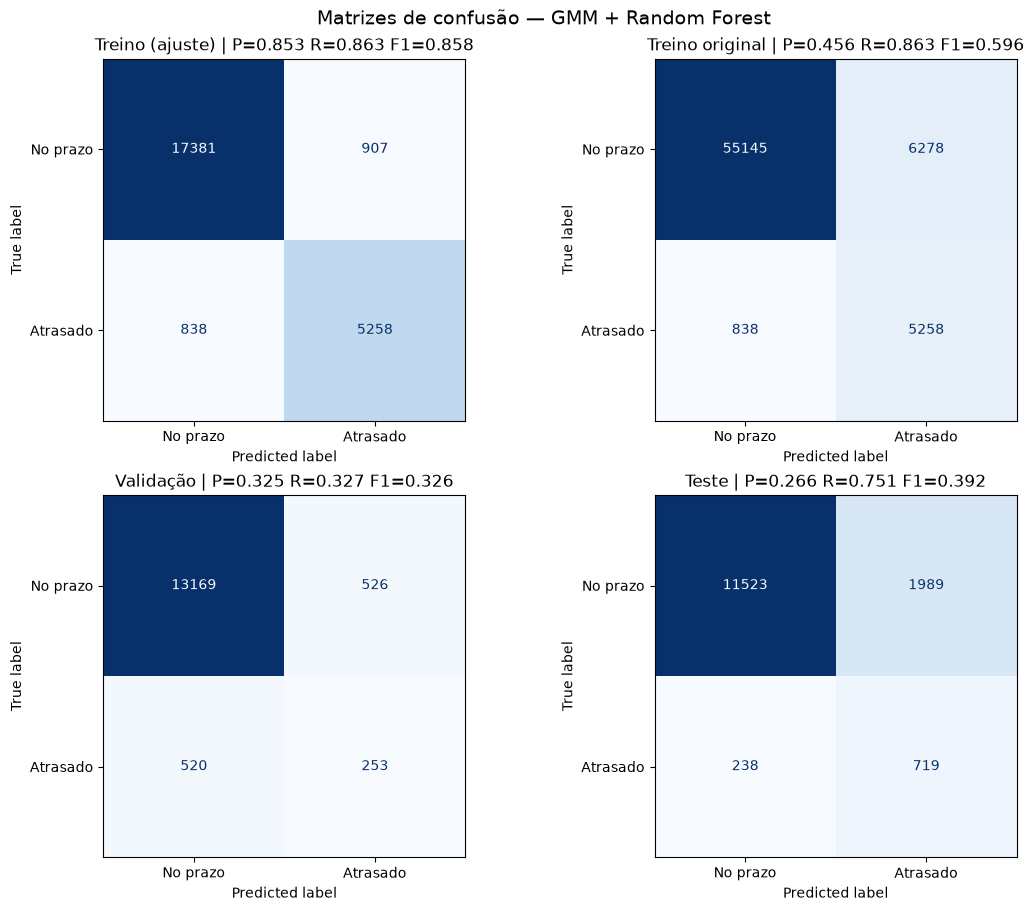

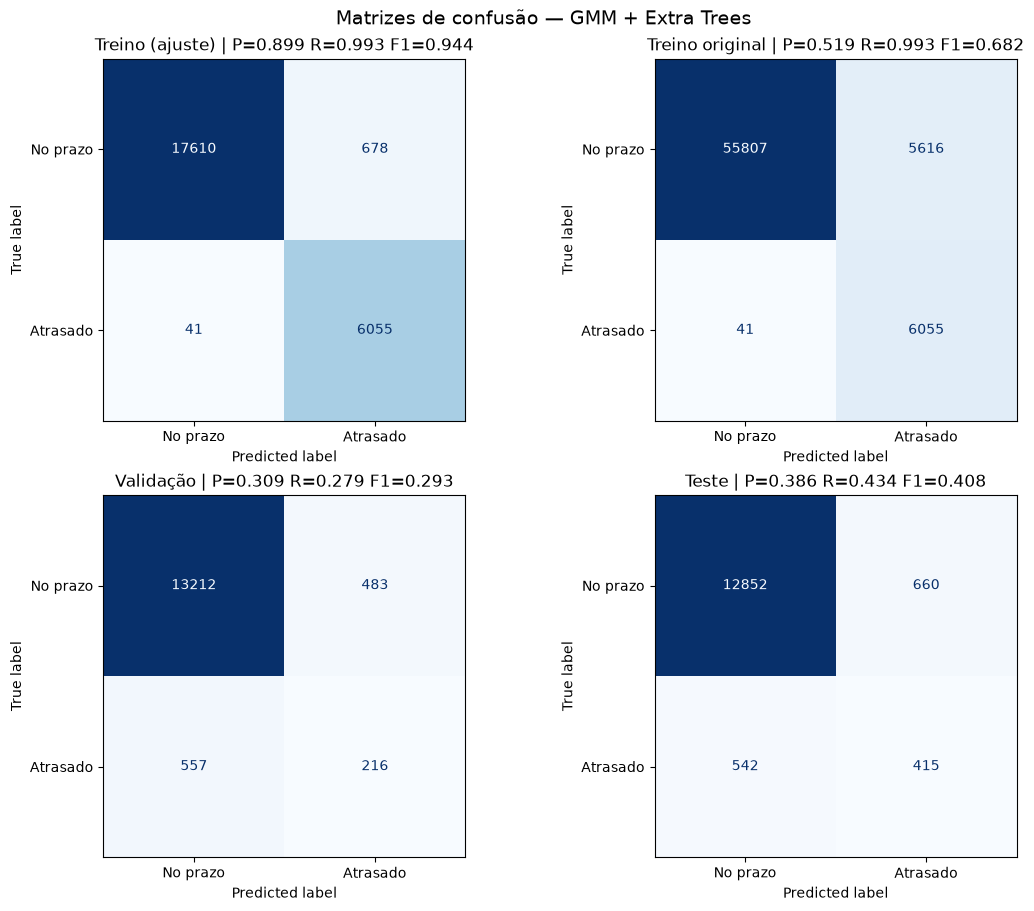

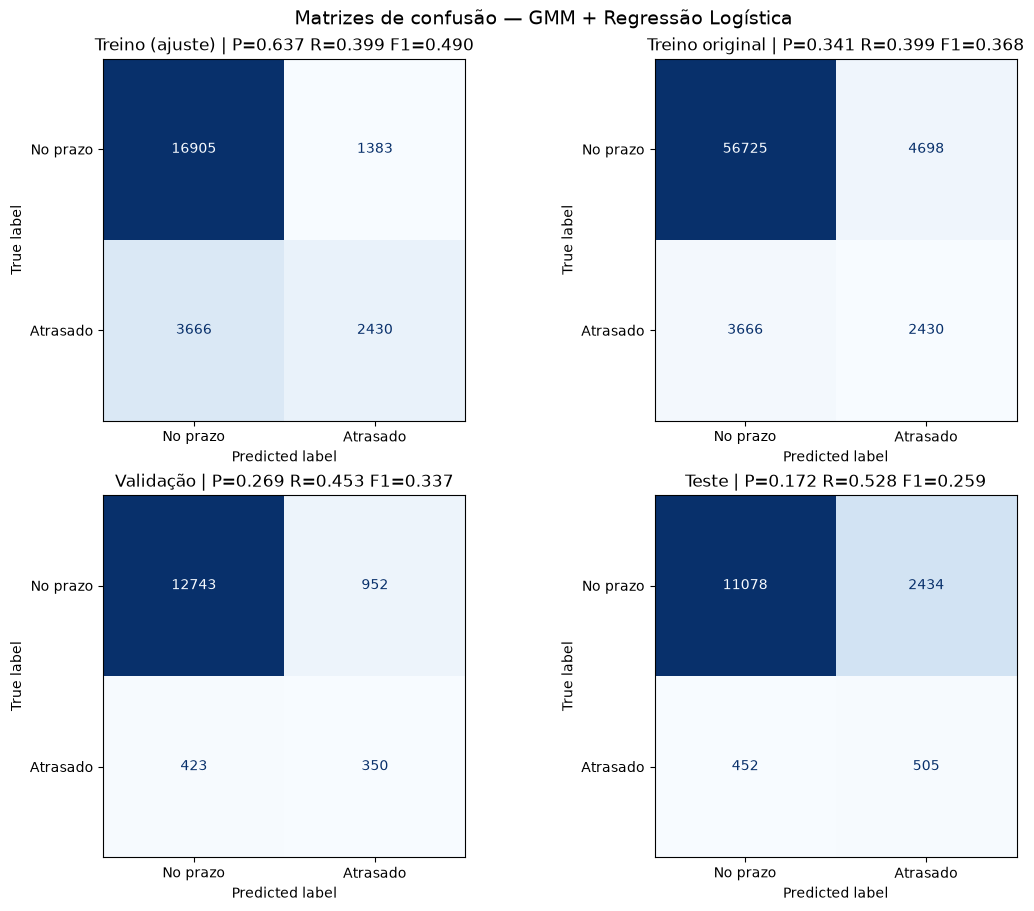

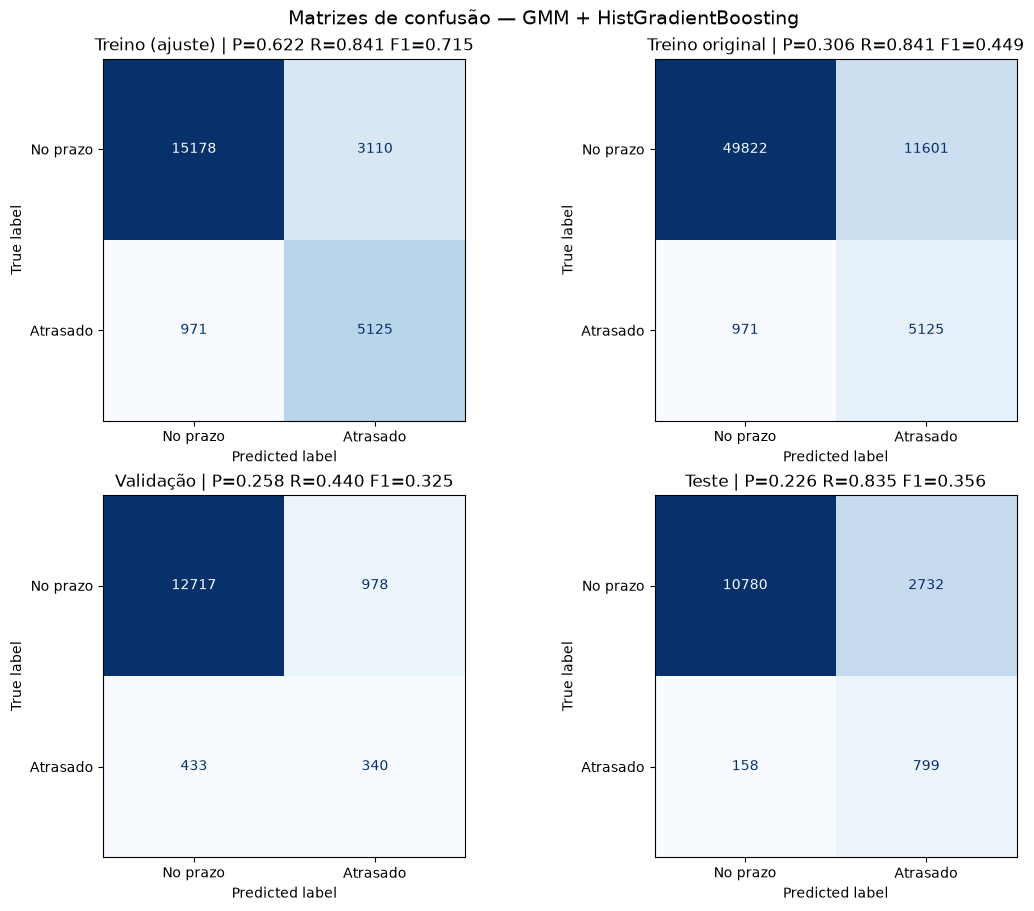

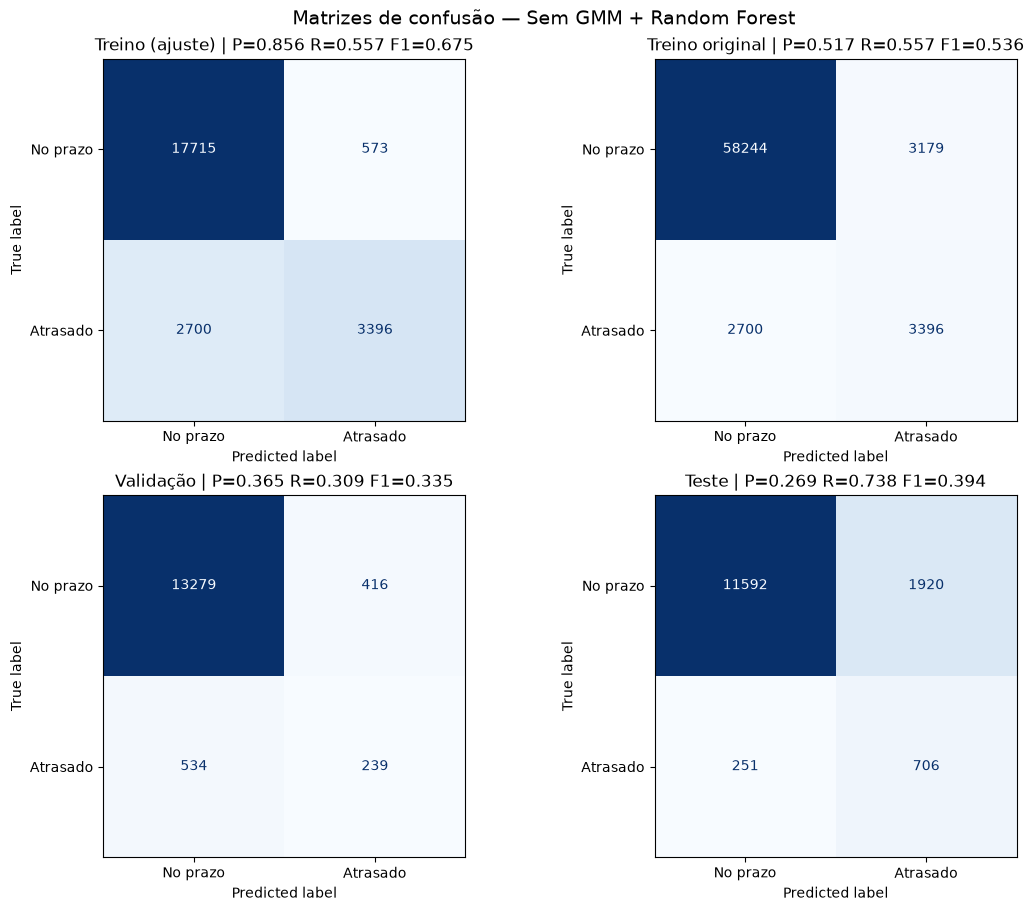

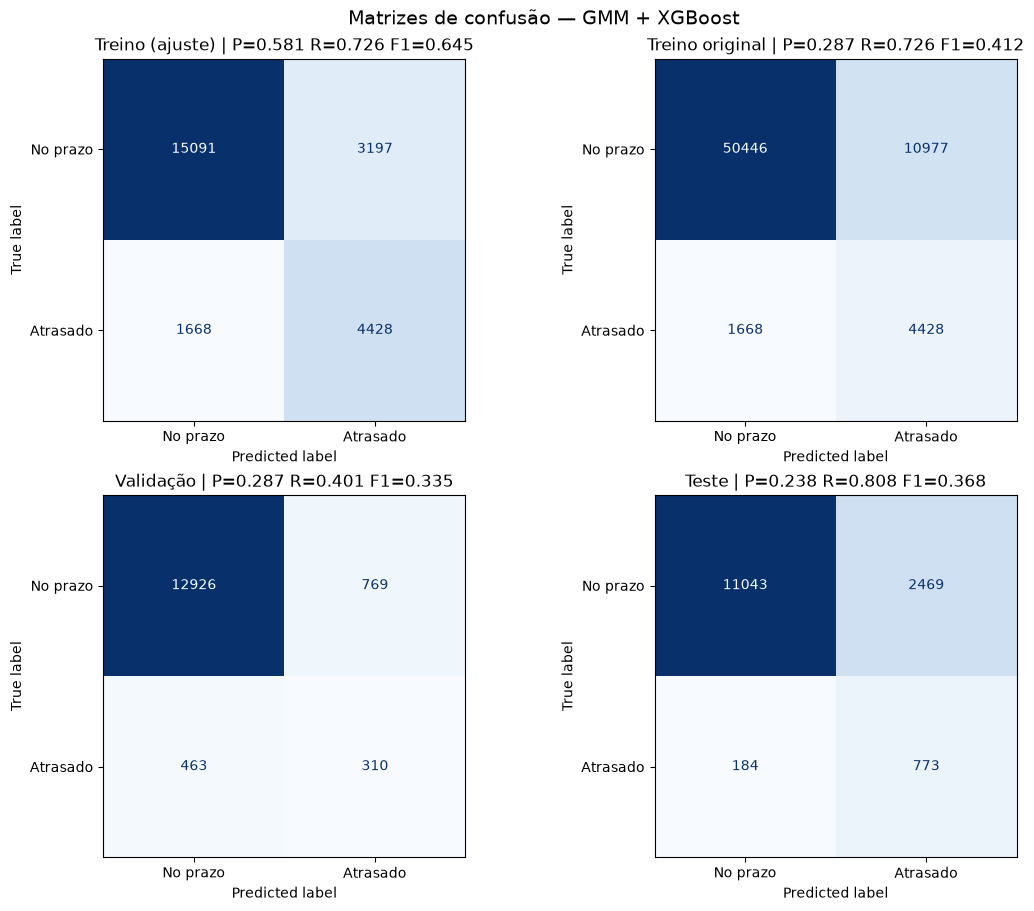

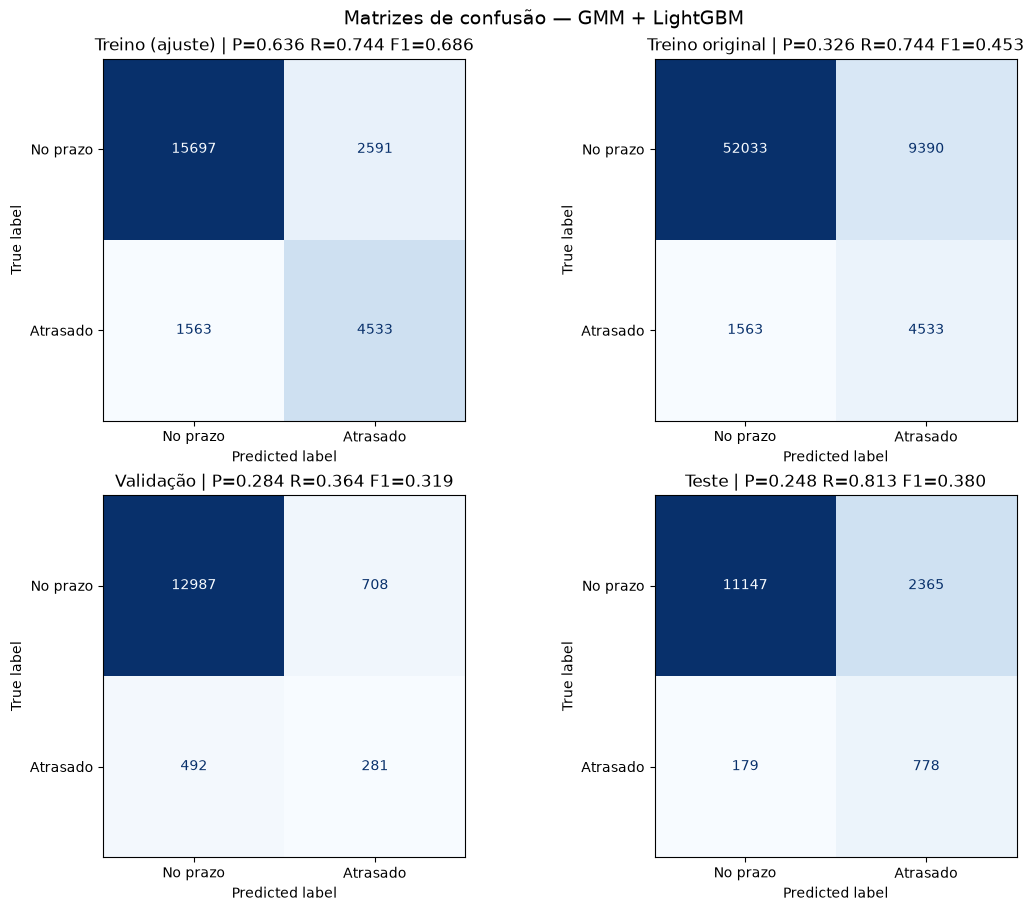

In [ ]:
# Matriz de confusão para TODOS os modelos e TODAS as divisões.
# Cada gráfico: treino usado, treino integral, validação e teste.
for nome, probs_divisao in probs_por_modelo.items():
    fig, axes = plt.subplots(2, 2, figsize=(11, 9), constrained_layout=True)
    fig.suptitle(f"Matrizes de confusão — {nome}", fontsize=14)
    for ax, divisao in zip(axes.ravel(), alvos.keys()):
        limiar = limiares_validados[nome]
        y_pred = (probs_divisao[divisao] >= limiar).astype(int)
        cm = confusion_matrix(alvos[divisao], y_pred, labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=["No prazo", "Atrasado"]).plot(
            ax=ax, cmap="Blues", colorbar=False, values_format="d")
        met = calcular_metricas(alvos[divisao], probs_divisao[divisao], limiar)
        ax.set_title(f"{divisao} | P={met['precision']:.3f} R={met['recall']:.3f} F1={met['f1']:.3f}")
    plt.show()

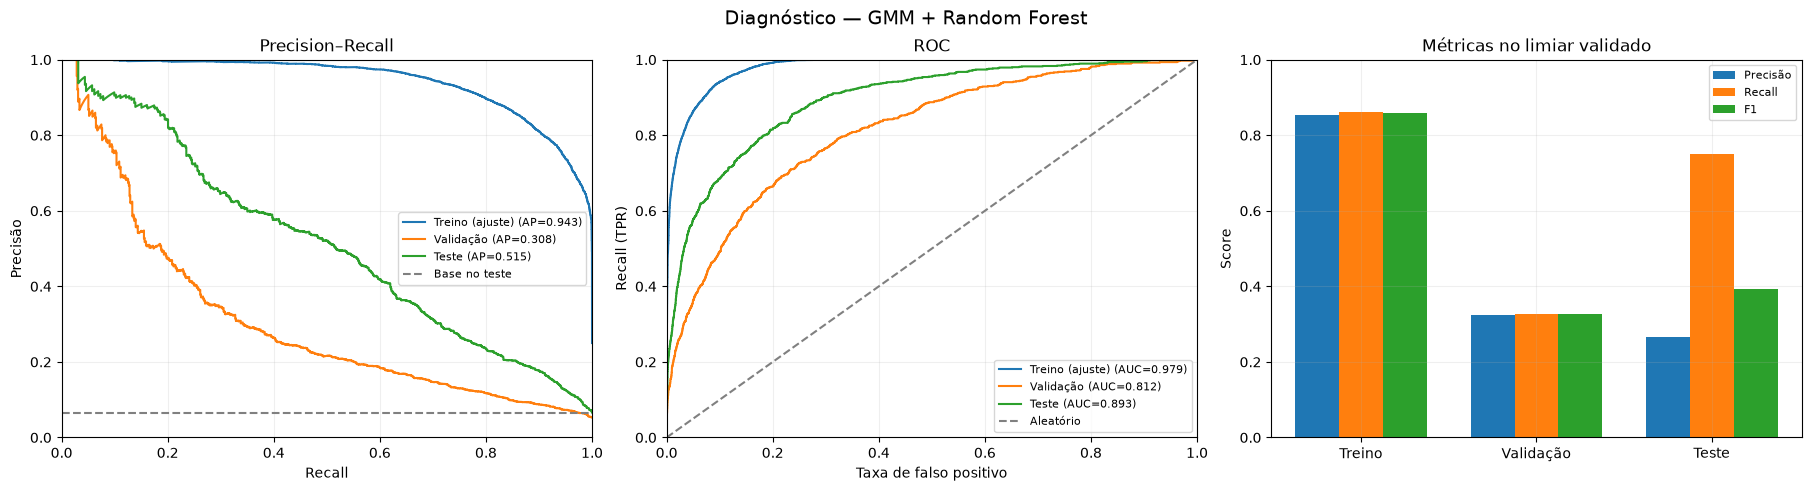

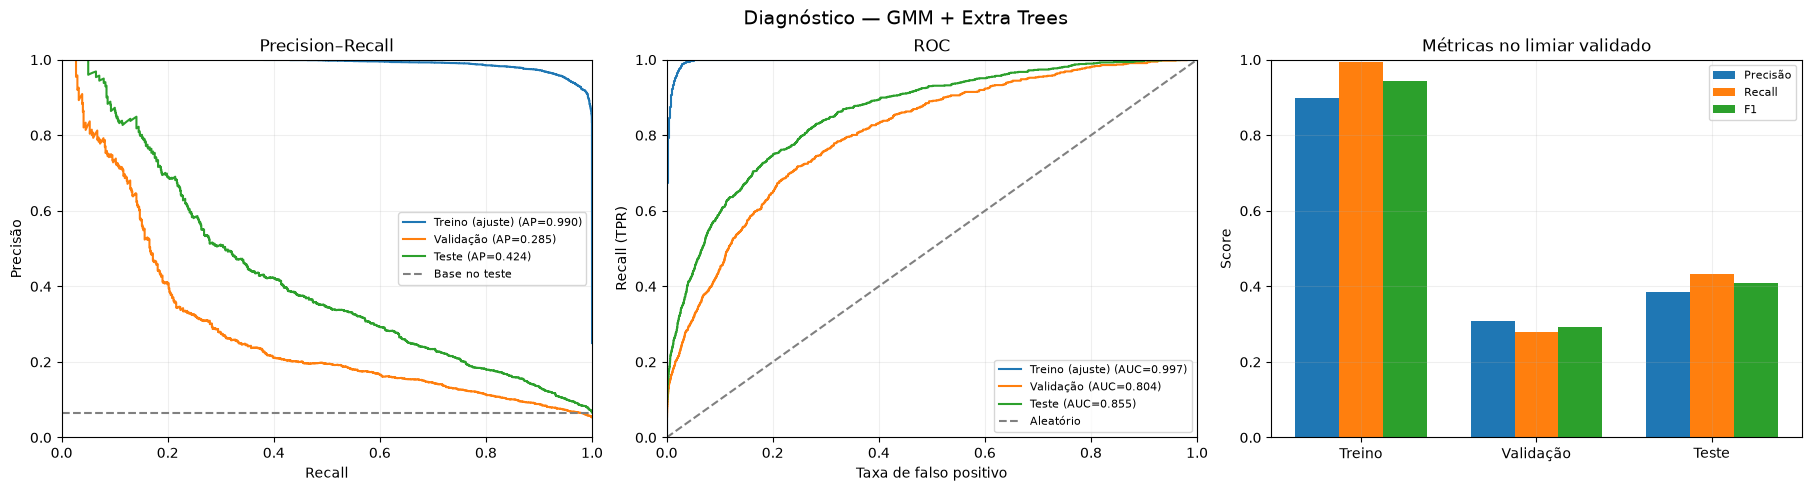

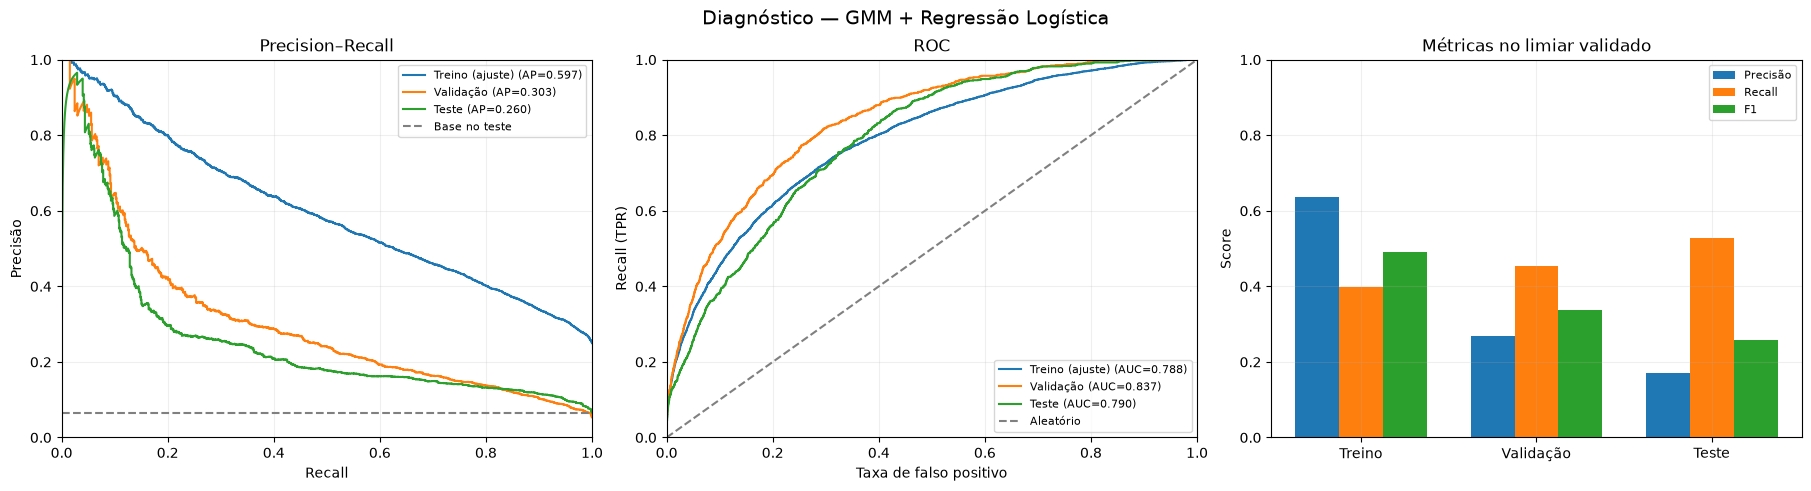

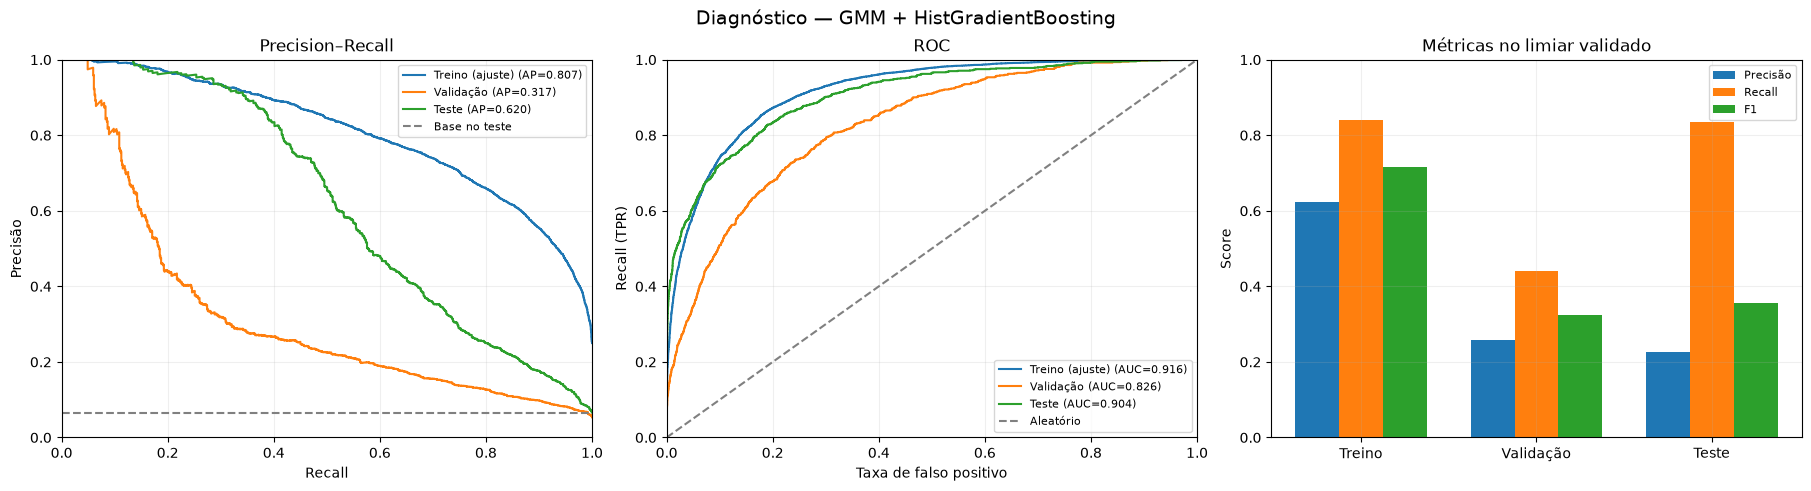

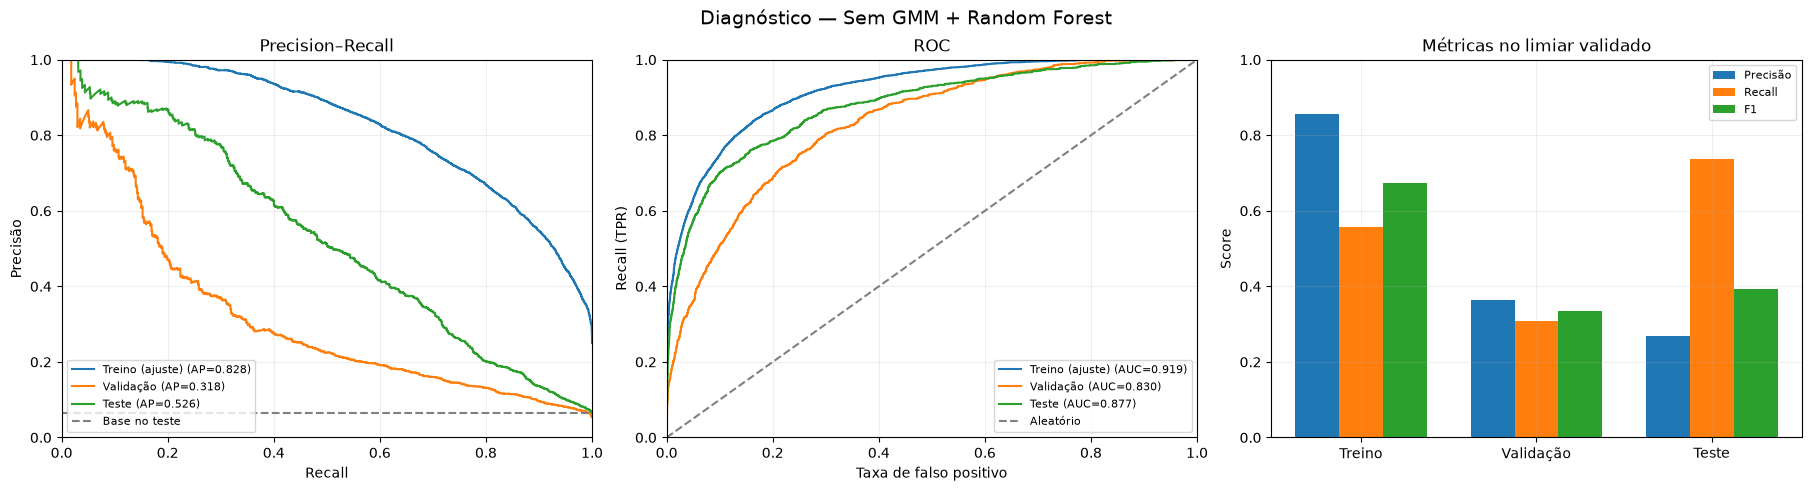

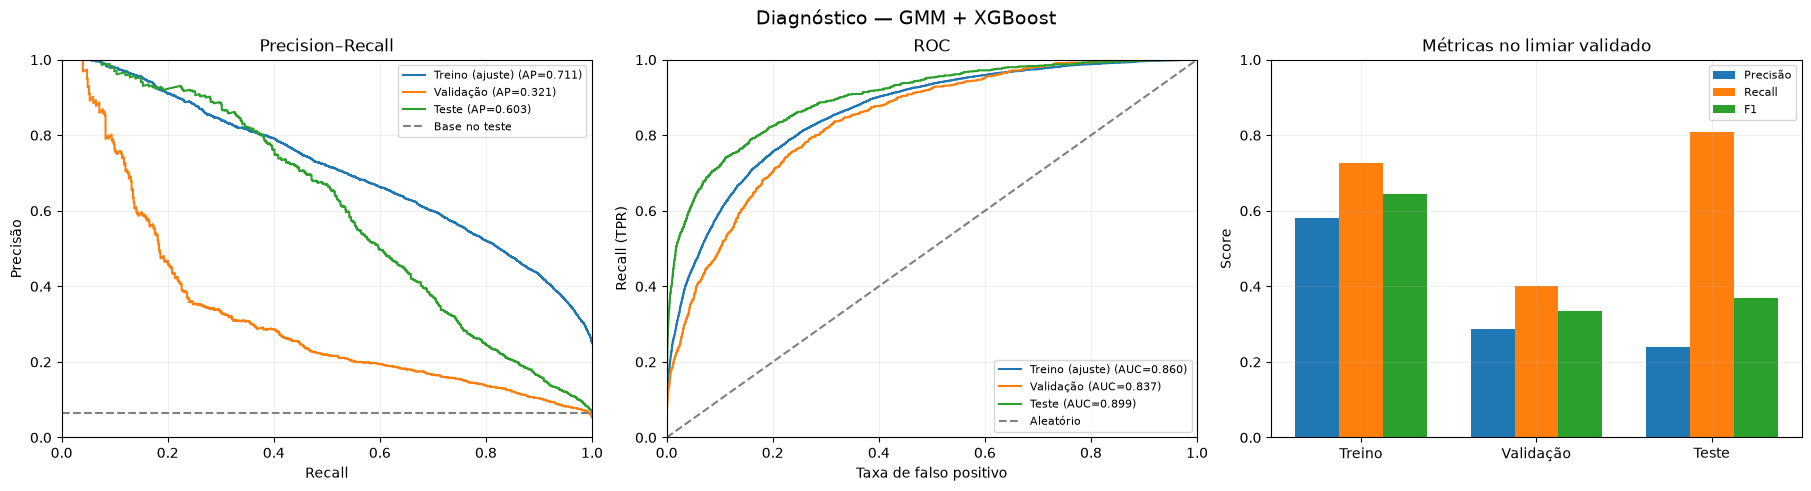

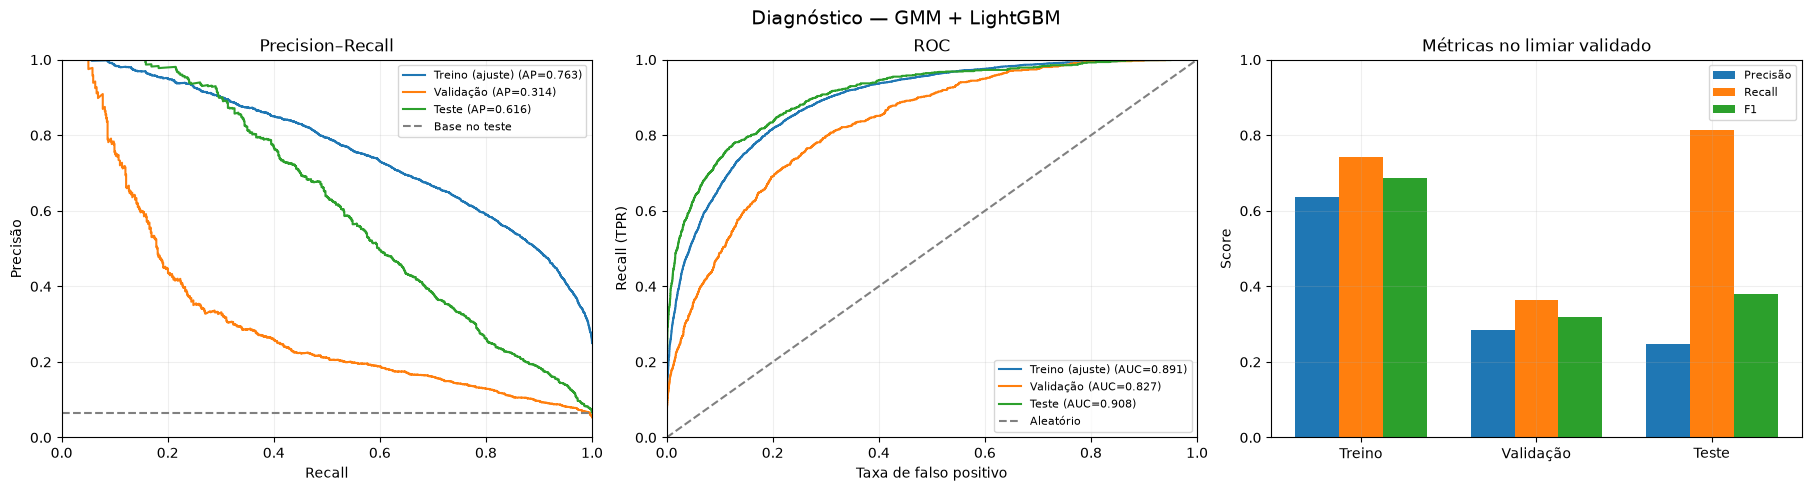

In [ ]:
# Os gráficos originais de Precision-Recall foram mantidos e ampliados:
# uma curva para treino, validação e teste em CADA modelo.
# Curva ROC + evolução de precisão, recall e F1 também para cada modelo.
for nome, dados_prob in probs_por_modelo.items():
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), constrained_layout=True)
    for divisao in ["Treino (ajuste)", "Validação", "Teste"]:
        y_arr = np.asarray(alvos[divisao]).astype(int).ravel()
        p = dados_prob[divisao]
        prec, rec, _ = precision_recall_curve(y_arr, p)
        axes[0].plot(rec, prec, label=f"{divisao} (AP={average_precision_score(y_arr,p):.3f})")
        fpr, tpr, _ = roc_curve(y_arr, p)
        axes[1].plot(fpr, tpr, label=f"{divisao} (AUC={roc_auc_score(y_arr,p):.3f})")
    axes[0].axhline(np.asarray(y_teste).mean(), color="gray", linestyle="--",
                    label="Base no teste")
    axes[0].set(title="Precision–Recall", xlabel="Recall", ylabel="Precisão", xlim=(0, 1), ylim=(0, 1))
    axes[1].plot([0,1], [0,1], linestyle="--", color="gray", label="Aleatório")
    axes[1].set(title="ROC", xlabel="Taxa de falso positivo", ylabel="Recall (TPR)", xlim=(0,1), ylim=(0,1))
    subconjunto = resultados_completos.query("modelo == @nome and divisao in ['Treino (ajuste)', 'Validação', 'Teste']")
    x = np.arange(len(subconjunto))
    width = 0.25
    for offset, metric, title in [(-width, "precision", "Precisão"), (0, "recall", "Recall"), (width, "f1", "F1")]:
        axes[2].bar(x + offset, subconjunto[metric], width=width, label=title)
    axes[2].set_xticks(x, ["Treino", "Validação", "Teste"])
    axes[2].set(title="Métricas no limiar validado", ylabel="Score", ylim=(0,1))
    for ax in axes:
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    fig.suptitle(f"Diagnóstico — {nome}", fontsize=14)
    plt.show()

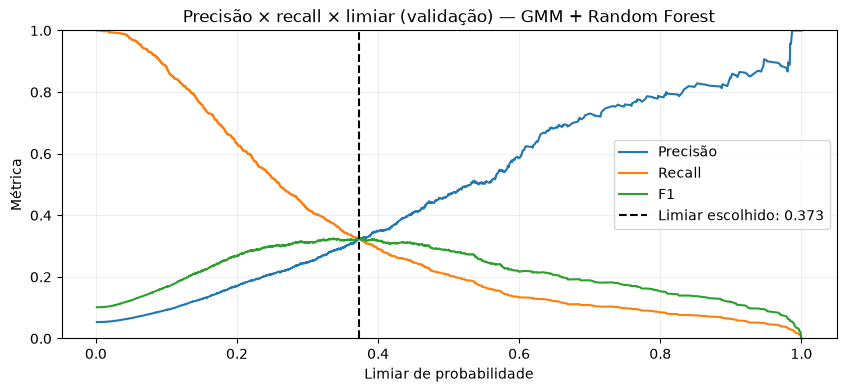

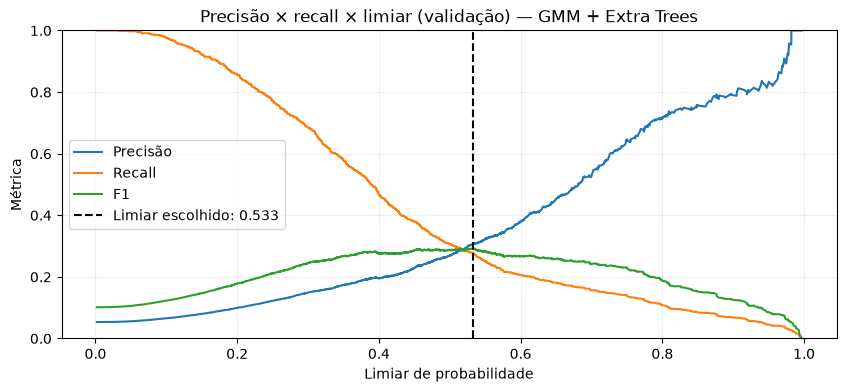

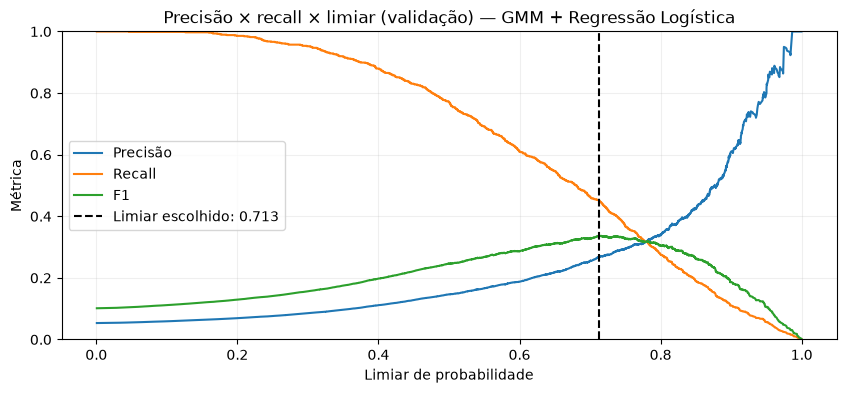

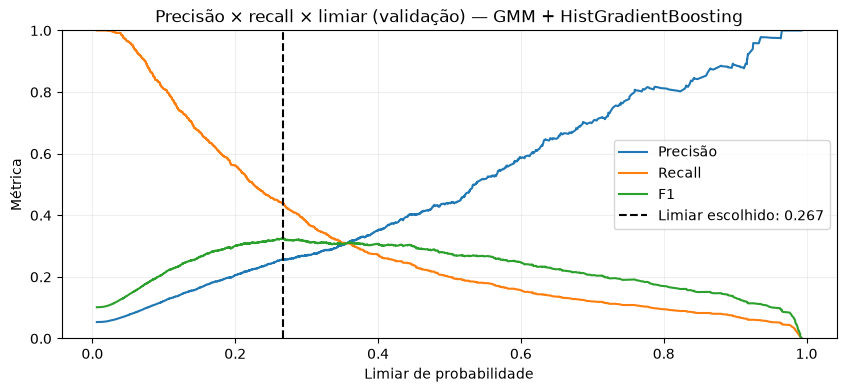

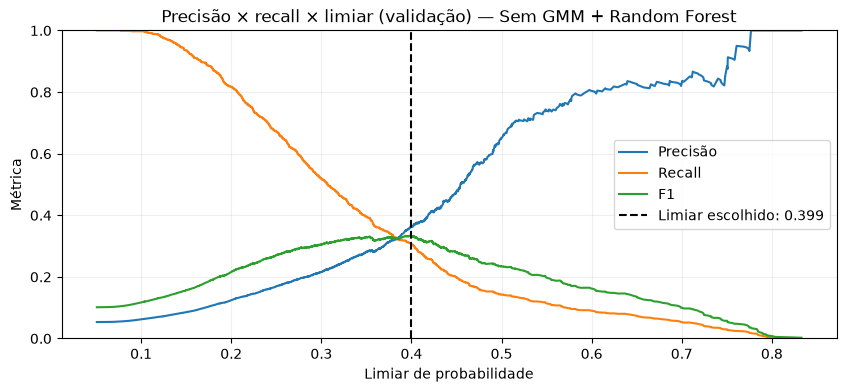

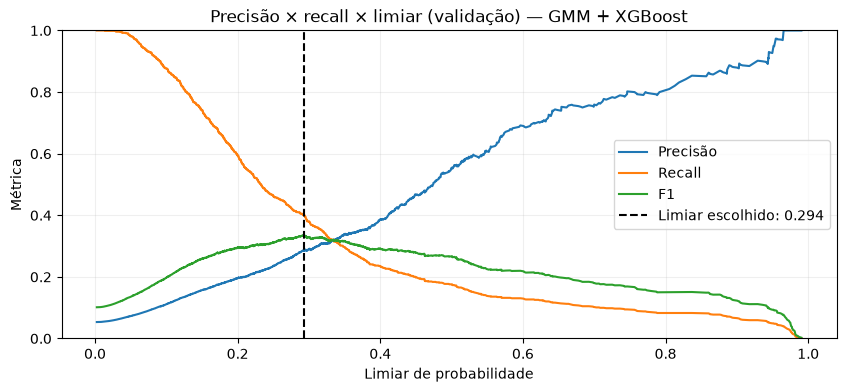

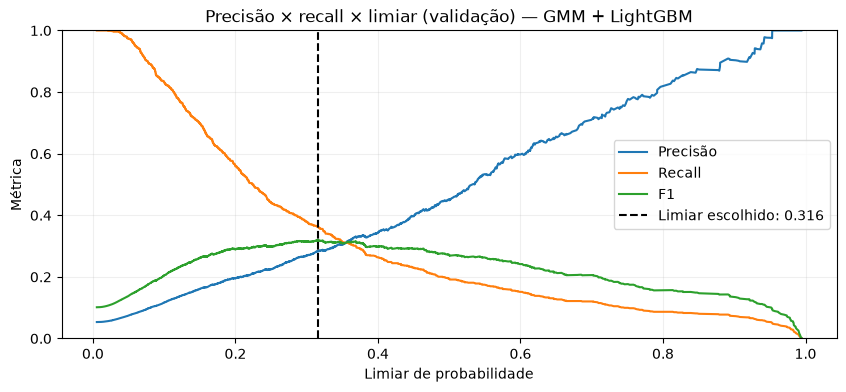

In [ ]:
# Gráfico adicional: como o limiar muda a precisão e o recall na VALIDAÇÃO.
# Útil para negociar o custo de um falso alerta versus deixar um atraso passar.
for nome, dados_prob in probs_por_modelo.items():
    proba = dados_prob["Validação"]
    prec, rec, th = precision_recall_curve(y_validacao, proba)
    if not len(th):
        continue
    f1_curva = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(th, prec[:-1], label="Precisão")
    ax.plot(th, rec[:-1], label="Recall")
    ax.plot(th, f1_curva, label="F1")
    ax.axvline(limiares_validados[nome], linestyle="--", color="black",
               label=f"Limiar escolhido: {limiares_validados[nome]:.3f}")
    ax.set(title=f"Precisão × recall × limiar (validação) — {nome}",
           xlabel="Limiar de probabilidade", ylabel="Métrica", ylim=(0,1))
    ax.legend()
    ax.grid(alpha=0.2)
    plt.show()

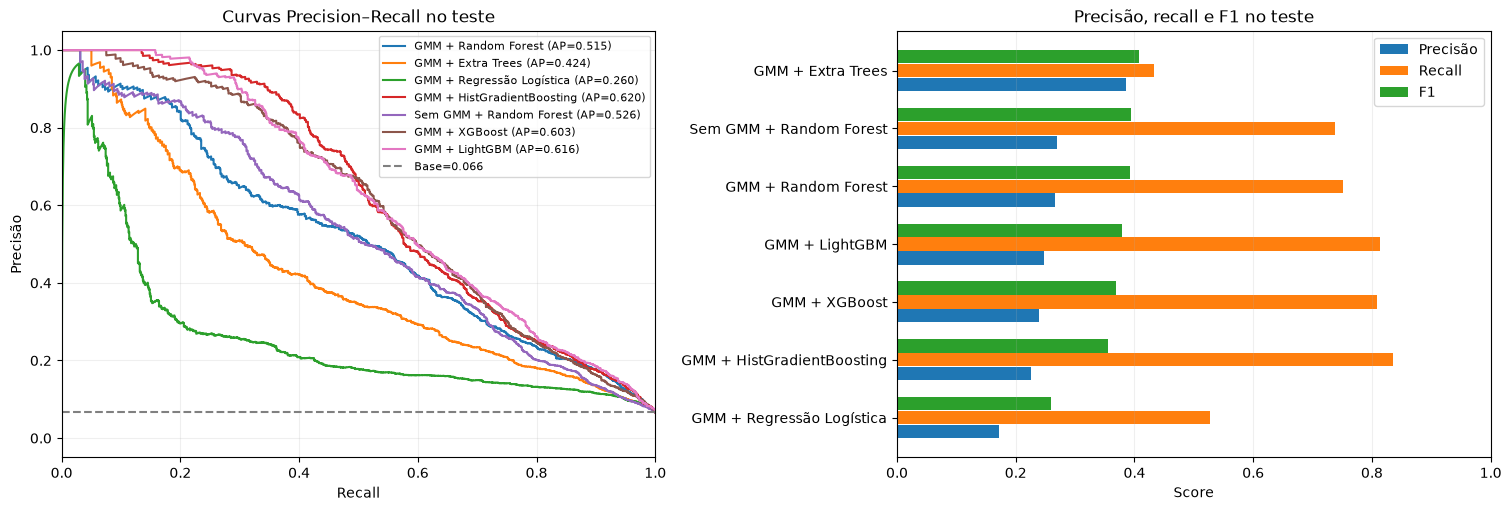

In [ ]:
# Comparação visual conjunta dos modelos no conjunto de teste.
# A seleção oficial já ocorreu na validação e NÃO deve ser refeita olhando este gráfico.
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for nome, prob in probs_por_modelo.items():
    precisao, recall, _ = precision_recall_curve(y_teste, prob["Teste"])
    ap = average_precision_score(y_teste, prob["Teste"])
    axes[0].plot(recall, precisao, label=f"{nome} (AP={ap:.3f})")
axes[0].axhline(float(np.asarray(y_teste).mean()), color="gray", linestyle="--",
                label=f"Base={np.asarray(y_teste).mean():.3f}")
axes[0].set(title="Curvas Precision–Recall no teste", xlabel="Recall", ylabel="Precisão", xlim=(0,1))
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.2)

ordem = resumo_teste.sort_values("f1", ascending=True)
indices = np.arange(len(ordem))
axes[1].barh(indices - 0.24, ordem["precision"], height=0.23, label="Precisão")
axes[1].barh(indices, ordem["recall"], height=0.23, label="Recall")
axes[1].barh(indices + 0.24, ordem["f1"], height=0.23, label="F1")
axes[1].set_yticks(indices, ordem["modelo"])
axes[1].set(title="Precisão, recall e F1 no teste", xlabel="Score", xlim=(0,1))
axes[1].legend()
axes[1].grid(axis="x", alpha=0.2)
plt.show()

In [ ]:
# Gráficos da rede neural: conservados para quando a MLP for ativada.
# A MLP não é treinada neste experimento.
if "MLP" not in historicos:
    print("MLP desativada. Random Forest, Extra Trees, regressão logística e boostings foram avaliados.")
else:
    historico = historicos["MLP"]
    for metrica, titulo in [("loss", "Loss"), ("auc", "ROC-AUC"), ("pr_auc", "PR-AUC")]:
        plt.figure(figsize=(9, 4))
        plt.plot(historico.history[metrica], label="Treino")
        plt.plot(historico.history["val_"+metrica], label="Validação")
        plt.title(f"MLP — Evolução de {titulo}")
        plt.xlabel("Épocas")
        plt.ylabel(titulo)
        plt.legend()
        plt.grid()
        plt.show()

MLP desativada. Random Forest, Extra Trees, regressão logística e boostings foram avaliados.


### Modelos adicionais (opcionais) — código para ativar depois

Os modelos adicionais e a rede neural **não são necessários** para executar a comparação. Para experimentar CatBoost ou MLP, adapte o exemplo abaixo em uma célula posterior usando **somente** as matrizes do treino e da validação e mantenha o teste exclusivamente para avaliação.

In [ ]:
# CATBOOST (opcional) — descomente se quiser inserir novas configurações:
# from catboost import CatBoostClassifier
# especificacoes["GMM + CatBoost"] = {
#     "usa_gmm": True, "classe": CatBoostClassifier,
#     "base": {"verbose": False, "random_seed": SEMENTE, "thread_count": 4},
#     "configuracoes": [
#         {"iterations": 300, "depth": 5, "learning_rate": 0.05},
#         {"iterations": 500, "depth": 6, "learning_rate": 0.035},
#     ]
# }
# Para treiná-lo, descomente acima e reexecute a célula de treino/seleção
# (que aparece ANTES da avaliação completa).

# MLP (rede neural, opcional) — somente depois de concluir comparação tabular:
# import tensorflow as tf
# from tensorflow import keras
# from tensorflow.keras import layers
# tf.keras.utils.set_random_seed(SEMENTE)
# X_mlp_treino = preparar_matriz("Treino (ajuste)", True, True)
# X_mlp_val = preparar_matriz("Validação", True, True)
# modelo_mlp = keras.Sequential([
#     layers.Input(shape=(X_mlp_treino.shape[1],)),
#     layers.Dense(128, activation="relu"), layers.BatchNormalization(),
#     layers.Dropout(0.3), layers.Dense(64, activation="relu"),
#     layers.Dropout(0.2), layers.Dense(1, activation="sigmoid")
# ])
# modelo_mlp.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
#                    loss="binary_crossentropy",
#                    metrics=[keras.metrics.AUC(name="auc"),
#                             keras.metrics.AUC(name="pr_auc", curve="PR")])
# historico_mlp = modelo_mlp.fit(
#     X_mlp_treino, y_treino_balanceado,
#     validation_data=(X_mlp_val, y_validacao),
#     epochs=100, batch_size=256,
#     callbacks=[keras.callbacks.EarlyStopping(
#         monitor="val_loss", patience=15, restore_best_weights=True)], verbose=1)
# historicos["MLP"] = historico_mlp
# Para COMPARAR MLP, adicione-o explicitamente à rotina de métricas/avaliação;
# ele não é registrado automaticamente no laço dos estimadores sklearn.

In [ ]:
# Salvamento: vencedor foi definido na validação; exportar modelo e limiar.
# Pipelines incluem o preprocessador (GMM se aplicável) e o estimador já ajustados.
# cloudpickle permite serializar as classes customizadas definidas no notebook.
with open("melhor_modelo_olist.pkl", "wb") as f:
    cloudpickle.dump(melhor_modelo, f)
with open("limiar_olist.txt", "w", encoding="utf-8") as f:
    f.write(str(melhor_limiar))

# Exportar resultados detalhados para comparar fora do notebook.
resultados_completos.to_csv("olist_metricas_treino_validacao_teste.csv", index=False)
historico_busca.to_csv("olist_ajuste_hiperparametros.csv", index=False)
print("Modelo selecionado pela validação:", melhor_nome)
print("Limiar selecionado pela validação:", melhor_limiar)
print("Arquivos exportados: melhor_modelo_olist.pkl, limiar_olist.txt,")
print("  olist_metricas_treino_validacao_teste.csv e olist_ajuste_hiperparametros.csv")
print("Não carregue modelos pickle/cloudpickle de fontes desconhecidas.")

Modelo selecionado pela validação: GMM + Regressão Logística
Limiar selecionado pela validação: 0.7125413239336023
Arquivos exportados: melhor_modelo_olist.pkl, limiar_olist.txt,
  olist_metricas_treino_validacao_teste.csv e olist_ajuste_hiperparametros.csv
Não carregue modelos pickle/cloudpickle de fontes desconhecidas.
